In [42]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
plt.style.use('ggplot')
import numpy as np
from collections import Counter
from scipy import stats
from scipy.stats import spearmanr,pearsonr


## Please change the folder_name below

In [2]:
df=pd.read_csv('/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.03/reconcILS_result.csv')


In [3]:
True_Duplication = pd.DataFrame(list(df[(df.Process == "True Process")]['Duplication']),columns=['Duplication'])
TRUE_NNI = pd.DataFrame(list(df[(df.Process == "True Process")]['NNI']),columns=['NNI'])
TRUE_Loss = pd.DataFrame(list(df[(df.Process == "True Process")]['Loss']),columns=['Loss'])
True_DLCILS= pd.DataFrame(list(df[(df.Process == "True Process")]['DLCILS']),columns=['DLCILS'])
True_Hemiplasy= pd.DataFrame(list(df[(df.Process == "True Process")]['Hemiplasy']),columns=['Hemiplasy'])
concat_true = pd.concat([True_Duplication,TRUE_Loss,TRUE_NNI,True_Hemiplasy],axis=1)




In [4]:
reconcILS_Duplication = pd.DataFrame(list(df[(df.Process == "reconcILS")]['Duplication']),columns=['Duplication'])
reconcILS_NNI = pd.DataFrame(list(df[(df.Process == "reconcILS")]['NNI']),columns=['NNI'])
reconcILS_Loss = pd.DataFrame(list(df[(df.Process == "reconcILS")]['Loss']),columns=['Loss'])
reconcILS_Hemiplasy= pd.DataFrame(list(df[(df.Process == "reconcILS")]['Hemiplasy']),columns=['Hemiplasy'])
concat_reconcILS = pd.concat([reconcILS_Duplication,reconcILS_Loss,reconcILS_NNI,reconcILS_Hemiplasy],axis=1)

In [5]:
ete_Duplication = pd.DataFrame(list(df[(df.Process == "ETE3")]['Duplication']),columns=['Duplication'])
#ete_NNI = pd.DataFrame(list(df[(df.Process == "ETE3")]['NNI']),columns=['NNI'])
ete_Loss = pd.DataFrame(list(df[(df.Process == "ETE3")]['Loss']),columns=['Loss'])
#True_ete= pd.DataFrame(list(df[(df.Process == "ETE3")]['DLCILS']),columns=['DLCILS'])
concat_e = pd.concat([ete_Duplication,ete_Loss],axis=1)

/tmp/ipykernel_692892/756334091.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(bbox_to_anchor=(100, 100))
/tmp/ipykernel_692892/756334091.py:21: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend().remove()


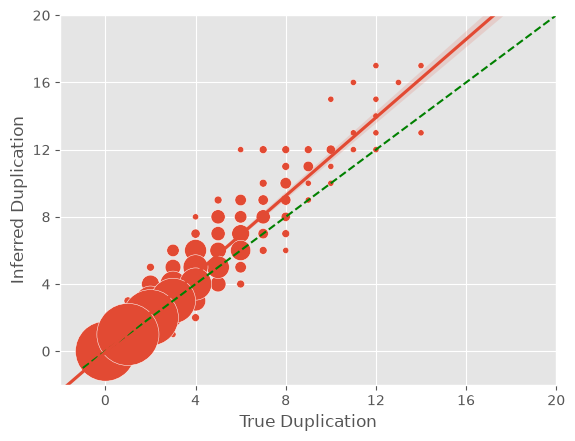

<Figure size 640x480 with 0 Axes>

In [6]:

result1 = pd.concat([True_Duplication['Duplication'], reconcILS_Duplication['Duplication']], ignore_index=True, axis=1)
result11 = result1.groupby([0, 1]).size().reset_index(name='Count')

result11 = result11.sort_values(by='Count', ascending=True)
x = [-1,1, 2, 3, 70]
y = [-1,1, 2, 3, 70]
ax = plt.plot(x, y, '--', color='g')
sns.scatterplot(data=result11, x=0, y=1, size="Count", legend=False, sizes=(20, 2000))
ax = sns.regplot(x=result1[0], y=result1[1], data=result1,marker="", truncate=False,fit_reg=True)

plt.xticks(np.arange(0, 21, 4))  
plt.yticks(np.arange(0, 21, 4))  
plt.xlabel("True Duplication")
plt.ylabel("Inferred Duplication")

ax.set_xlim(-2, 20)
ax.set_ylim(-2, 20)

plt.legend(bbox_to_anchor=(100, 100))
plt.savefig('regex_dups_reconcILS_large.png', dpi=500)
plt.legend().remove()
plt.show()
plt.clf()


/tmp/ipykernel_692892/2151146559.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(bbox_to_anchor=(100, 100))
/tmp/ipykernel_692892/2151146559.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend().remove()


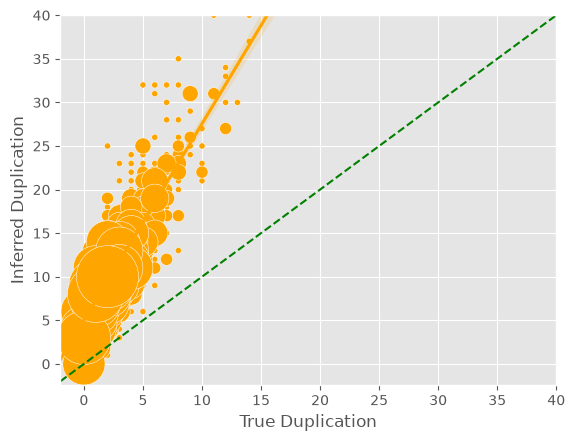

<Figure size 640x480 with 0 Axes>

In [7]:

result1 = pd.concat([True_Duplication['Duplication'], ete_Duplication['Duplication']], ignore_index=True, axis=1)
result11 = result1.groupby([0, 1]).size().reset_index(name='Count')

result11 = result11.sort_values(by='Count', ascending=True)
x = [-5,1, 2, 3, 50]
y = [-5,1, 2, 3, 50]
ax = plt.plot(x, y, '--', color='g')
sns.scatterplot(data=result11, x=0, y=1, size="Count",color='orange',legend=False, sizes=(20, 2000))
ax = sns.regplot(x=result1[0], y=result1[1], data=result1,color='orange',marker="", truncate=False,fit_reg=True)

 
plt.xlabel("True Duplication")
plt.ylabel("Inferred Duplication")

ax.set_xlim(-2, 40)
ax.set_ylim(-2.4, 40)

plt.legend(bbox_to_anchor=(100, 100))
plt.savefig('regex_dups_ete3_large.png', dpi=500)
plt.legend().remove()
plt.show()
plt.clf()


/tmp/ipykernel_692892/4238093003.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(bbox_to_anchor=(100,100))
/tmp/ipykernel_692892/4238093003.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend().remove()


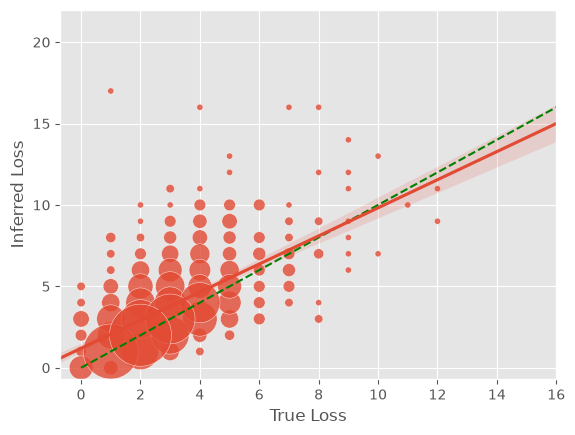

<Figure size 640x480 with 0 Axes>

In [8]:

result1 =pd.concat([TRUE_Loss['Loss'],reconcILS_Loss['Loss']], ignore_index=True,axis=1)
result11=result1.groupby([0,1]).size().reset_index(name='Count')

x = [0,1, 2, 3, 4, 5,6,16]
y = [0,1, 2, 3, 4, 5,6,16]
line = plt.plot(x, y, '--',color='g')

result11 = result11.sort_values(by='Count', ascending=True)

sns.scatterplot(data=result11, x=0, y=1, size="Count", legend=False, sizes=(20, 2000), alpha=0.8)
ax=sns.regplot(x=result1[0], y=result1[1], data=result1,marker="", truncate=False,fit_reg=True, scatter_kws={'alpha':1})


plt.xlabel("True Loss")
plt.ylabel("Inferred Loss")
ax.set_xlim(-0.7, 16)
ax.set_ylim(-0.7, 22)
plt.legend(bbox_to_anchor=(100,100))
plt.legend().remove()

plt.savefig('regex_loss_reconcILS_large.png', dpi=500)

plt.show()
plt.clf()

/tmp/ipykernel_692892/2362354971.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(bbox_to_anchor=(100,100))
/tmp/ipykernel_692892/2362354971.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend().remove()


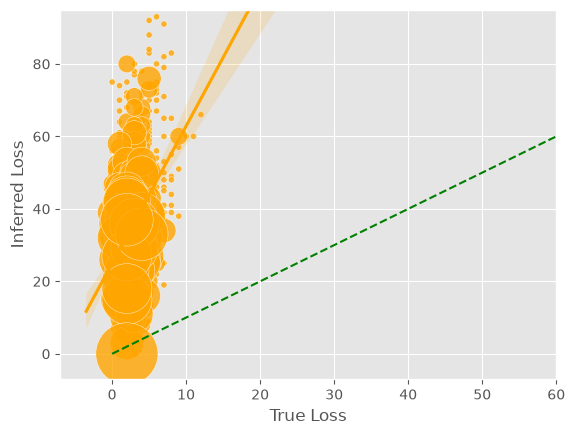

<Figure size 640x480 with 0 Axes>

In [9]:

result1 =pd.concat([TRUE_Loss['Loss'],ete_Loss['Loss']], ignore_index=True,axis=1)
result11=result1.groupby([0,1]).size().reset_index(name='Count')

x = [0,1, 2, 3, 4, 5,6,7,8,9,70]
y = [0,1, 2, 3, 4, 5,6,7,8,9,70]
line = plt.plot(x, y, '--',color='g')

result11 = result11.sort_values(by='Count', ascending=True)

sns.scatterplot(data=result11, x=0, y=1, size="Count", color='orange',legend=False, sizes=(20, 2000), alpha=0.8)
ax=sns.regplot(x=result1[0], y=result1[1], data=result1,marker="", color='orange',truncate=False,fit_reg=True, scatter_kws={'alpha':1})


plt.xlabel("True Loss")
plt.ylabel("Inferred Loss")
ax.set_xlim(-7, 60)
ax.set_ylim(-7, 95)
plt.legend(bbox_to_anchor=(100,100))
plt.legend().remove()

plt.savefig('regex_loss_ete_large.png', dpi=500)

plt.show()
plt.clf()

/tmp/ipykernel_692892/1601006049.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(bbox_to_anchor=(100,100))
/tmp/ipykernel_692892/1601006049.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend().remove()


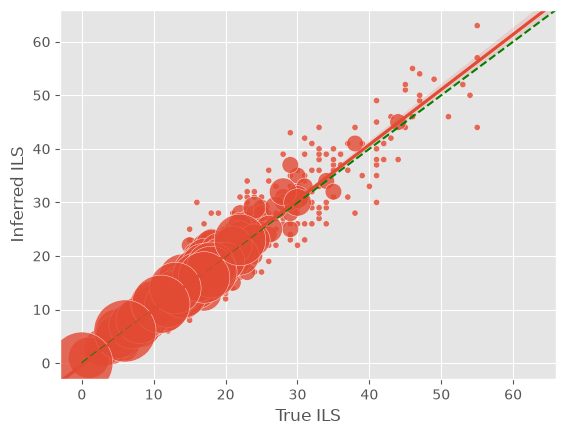

<Figure size 640x480 with 0 Axes>

In [10]:

result1 =pd.concat([TRUE_NNI['NNI'],reconcILS_NNI['NNI']], ignore_index=True,axis=1)
result11=result1.groupby([0,1]).size().reset_index(name='Count')

x = [0,1, 2, 3, 4, 5,6,7,8,9,10,11,12,13,14,15,66]
y = [0,1, 2, 3, 4, 5,6,7,8,9,10,11,12,13,14,15,66]
line = plt.plot(x, y, '--',color='g')
result11 = result11.sort_values(by='Count', ascending=True)

sns.scatterplot(data=result11, x=0, y=1, size="Count", legend=False, sizes=(20, 2000), alpha=0.8)
ax=sns.regplot(x=result1[0], y=result1[1], data=result1,marker="",truncate=False, fit_reg=True)



plt.xlabel("True ILS")
plt.ylabel("Inferred ILS")
ax.set_xlim(-3, 66)
ax.set_ylim(-3, 66)

plt.legend(bbox_to_anchor=(100,100))
plt.legend().remove()

plt.savefig('regex_NNI_reconcILS_large.png', dpi=500)

plt.show()
plt.clf()

In [39]:

import pandas as pd
from scipy.stats import spearmanr, pearsonr
from sklearn.metrics import mean_absolute_error, median_absolute_error
from sklearn.metrics.pairwise import cosine_similarity, cosine_distances
def stst(dataset,mu,labda,method,cost,file,results,flag):
    
    df = pd.read_csv(file)
    #tdf = df[(df.Gene_tree != 'None')][['Replicate', 'Duplication', 'Loss', 'NNI']].copy()
   # Find replicates with missing gene trees
    missing = df['Gene_tree'].astype('string').str.strip().str.rstrip(';').eq('None')
    missing = missing | df['Gene_tree'].isna()
    
    bad_reps = df.loc[missing, 'Replicate'].unique()
    
    # Exclude those replicates entirely
    tdf = df.loc[
        ~df['Replicate'].isin(bad_reps),
        ['Replicate', 'Duplication', 'Loss', 'NNI','DLCILS']
    ].copy()
        
    # Get replicate IDs with NO hemiplasy in True Process
    valid_replicates = tdf['Replicate'].unique()
    
    print(len(valid_replicates))
    
    df = df[(df['Replicate'].isin(valid_replicates))]
    print(len(df))
    mean= df[df["Process"] == "True Process"][["Duplication", "Loss","NNI"]].mean()

   
        
    metrics = ["Duplication", "Loss", "NNI"]
    if method=='ETE3':
        metrics = ["Duplication", "Loss"]
    elif method=='DLCpar':
        metrics = ["Duplication", "Loss", "DLCILS"]

    true = df[df["Process"] == "True Process"].set_index("Replicate")
    inferred = df[df["Process"] == method].set_index("Replicate")
    print(len(true))
    print(len(inferred))
    #rint(true)

    #print(inferred)
    for metric in metrics:
        trueE=true[[metric]]
        true_metric=metric
        
        if flag and metric=='NNI':
            trueE=true[['DLCILS']]
            true_metric='DLCILS'
        
        # Align by Replicate
        paired = trueE.join(
            inferred[[metric]],
            how="inner",
            lsuffix="_true",
            rsuffix="_reconcILS"
        ).dropna()
    
        if flag and metric=='NNI':
            y_true = paired[f"{true_metric}"]
            y_pred = paired[f"{metric}"]
        else:
            y_true = paired[f"{true_metric}_true"]
            y_pred = paired[f"{metric}_reconcILS"]

        #result["id"].append(name)
        print(len(y_true),len(y_pred))
        result['Average_Duplication'].append(mean['Duplication'])
        result['Average_Loss'].append(mean['Loss'])
        result['Average_NNI'].append(mean['NNI'])
        result['mu'].append(mu)
        result['dataset x scale'].append(dataset)
        result['lambda'].append(labda)
        result['cost'].append(cost)
        result['method'].append(method)
        #result['scale'].append(scale)
        result["Metric"].append(metric)
        result["Pearson"].append(pearsonr(y_true, y_pred).statistic)
        result["Spearman"].append(spearmanr(y_true, y_pred).statistic)
        result["MAE"].append(mean_absolute_error(y_true, y_pred))
        result["MedianAE"].append(median_absolute_error(y_true, y_pred))

        
        u_2d = np.array(y_true).reshape(1, -1)
        v_2d = np.array(y_pred).reshape(1, -1)
        
        # Compute similarity (returns a 2D matrix)
        similarity_matrix = cosine_similarity(u_2d, v_2d)
        
        # Extract the scalar value
        similarity_score = similarity_matrix[0, 0]
        #print(similarity_score) # Output: ~0.9746
        result["Cosine"].append(similarity_score)

    return result

In [8]:


result = {
        "dataset x scale": [],
        "mu": [],
        "lambda": [],
        "method":[],
        "cost": [],
        "Metric": [],
        "Pearson": [],
        "Spearman": [],
        "MAE": [],
        "MedianAE": [],
        "Cosine": []
    
    
    }
result= stst('40sp x 1','dupcoal: 0.03','dupcoal: 0.03','reconcILS','default', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.03/reconcILS_result_1.1_1_1.csv',result,False)
result= stst('40sp x 1','dupcoal: 0.03','dupcoal: 0.03','reconcILS','D=3,I=1,L=4', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.03/reconcILS_result_3_1_4.csv',result,False)
result= stst('40sp x 1','dupcoal: 0.03','dupcoal: 0.03','reconcILS','D=1,I=5,L=1', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.03/reconcILS_result_1_5_1.csv',result,False)




result= stst('40sp x 1000','dupcoal: 0.00003','dupcoal: 0.00003','reconcILS','default', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.00003_0.00003_x1000/reconcILS_result_1.1_1_1.csv',result,False)

result= stst('40sp x 1','dupcoal: 0.03','dupcoal: 0.03','ETE3','default', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.03/reconcILS_result_1.1_1_1.csv',result,False)

result= stst('40sp x 1000','dupcoal: 0.00003','dupcoal: 0.00003','ETE3','default', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.00003_0.00003_x1000/reconcILS_result_1.1_1_1.csv',result,False)

result= stst('16sp x 0.1','dupcoal: 0.0015','dupcoal: 0.003','reconcILS','reconcILS default', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication__fungi_1_0_1_0.0015_0.003/_1_result_1.1_1_1.csv',result,False)
result= stst('16sp x 0.1','dupcoal: 0.0015','dupcoal: 0.003','reconcILS','D=2,I=1,L=2', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication__fungi_1_0_1_0.0015_0.003/_1_result_2_1_2.csv',result,False)

result= stst('16sp x 0.1','dupcoal: 0.0015','dupcoal: 0.003','DLCpar','reconILS default', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication__fungi_1_0_1_0.0015_0.003/_1_result_1.1_1_1.csv',result,False)
result= stst('16sp x 0.1','dupcoal: 0.0015','dupcoal: 0.003','DLCpar','D=2,I=1,L=2', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication__fungi_1_0_1_0.0015_0.003/_1_result_2_1_2.csv',result,False)

result= stst('16sp x 0.1','dupcoal: 0.0015','dupcoal: 0.003','ETE3','default', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication__fungi_1_0_1_0.0015_0.003/_1_result_1.1_1_1.csv',result,False)


result= stst('40sp x 1','dupcoal: 0.01','dupcoal: 0.03','reconcILS','default', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.01_0.03/reconcILS_result.csv',result,False)
result= stst('40sp x 1','dupcoal: 0.03','dupcoal: 0.01','reconcILS','default', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.01/reconcILS_result.csv',result,False)


result= stst('40sp x 1','dupcoal: 0.01','dupcoal: 0.03','ETE3','default', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.01_0.03/reconcILS_result.csv',result,False)
result= stst('40sp x 1','dupcoal: 0.03','dupcoal: 0.01','ETE3','default', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.01/reconcILS_result.csv',result,False)



result= stst('40sp x 1','dupcoal: 0.0001','dupcoal: 0.03','reconcILS','default', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.0001_0.03/reconcILS_result_1.1_1_1.csv',result,False)
result= stst('40sp x 1','dupcoal: 0.03','dupcoal: 0.0001','reconcILS','default', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.0001/reconcILS_result_1.1_1_1.csv',result,False)


result= stst('40sp x 1','dupcoal: 0.0001','dupcoal: 0.03','ETE3','default', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.0001_0.03/reconcILS_result_1.1_1_1.csv',result,False)
result= stst('40sp x 1','dupcoal: 0.03','dupcoal: 0.0001','ETE3','default', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.0001/reconcILS_result_1.1_1_1.csv',result,False)

#fungi_scaled_0.1.tre --mu_par 0.0015 --lambda_par 0.003
#result= stst('dupcoal: 0.01','dupcoal: 0.03', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.01_0.03/reconcILS_result.csv',result,False)
#result= stst('dupcoal: 0.03','dupcoal: 0.01', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.01/reconcILS_result.csv',result,False)
result= stst('40sp x 1 error 5','dupcoal: 0.03','dupcoal: 0.03','reconcILS','default', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.03/results_err_5/reconcILS_result_1.1_1_1.csv',result,False)
result= stst('40sp x 1 error 5','dupcoal: 0.03','dupcoal: 0.03','ETE3','default', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.03/results_err_5/reconcILS_result_1.1_1_1.csv',result,False)
result= stst('40sp x 1 error 10','dupcoal: 0.03','dupcoal: 0.03','reconcILS','default', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.03/results_err_10/reconcILS_result_1.1_1_1.csv',result,False)
result= stst('40sp x 1 error 10','dupcoal: 0.03','dupcoal: 0.03','ETE3','default', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.03/results_err_10/reconcILS_result_1.1_1_1.csv',result,False)

result= stst('40sp x 1 error 15','dupcoal: 0.03','dupcoal: 0.03','reconcILS','default', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.03/results_err_15/reconcILS_result_1.1_1_1.csv',result,False)
result= stst('40sp x 1 error 15','dupcoal: 0.03','dupcoal: 0.03','ETE3','default', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.03/results_err_15/reconcILS_result_1.1_1_1.csv',result,False)
result= stst('3sp x 1','dupcoal: 0.15','dupcoal: 0.3','reconcILS','default', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_3_0.1_0.3/_1_result_1.1_1_1.csv',result,False)
result= stst('3sp x 1','dupcoal: 0.15','dupcoal: 0.3','ETE3','default', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_3_0.1_0.3/_1_result_1.1_1_1.csv',result,False)
result= stst('3sp x 1','dupcoal: 0.15','dupcoal: 0.3','DLCpar','default', '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_3_0.1_0.3/_1_result_1.1_1_1.csv',result,False)

'''
for er in range(9):
    result= stst(f'40sp  {er}','dupcoal: 0.03','dupcoal: 0.03','reconcILS','default', f'/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.03_0{er+1}/reconcILS_result_1.1_1_1.csv',result,False)
    result= stst(f'40sp  {er}','dupcoal: 0.03','dupcoal: 0.03','ETE3','default', f'/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.03_0{er+1}/reconcILS_result_1.1_1_1.csv',result,False)

    
result= stst('40sp 10','dupcoal: 0.03','dupcoal: 0.03','reconcILS','default', f'/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.03_10/reconcILS_result_1.1_1_1.csv',result,False)
result= stst('40sp 10','dupcoal: 0.03','dupcoal: 0.03','ETE3','default', f'/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.03_10/reconcILS_result_1.1_1_1.csv',result,False)
'''

pd.DataFrame(result).to_csv('grand_results.csv',index=False)

985
2955
985
985
985 985
985 985
985 985
985
2955
985
985
985 985
985 985
985 985
985
2955
985
985
985 985
985 985
985 985
980
2940
980
980
980 980
980 980
980 980
985
2955
985
985
985 985
985 985
980
2940
980
980
980 980
980 980
1000
4000
1000
1000
1000 1000
1000 1000
1000 1000
1000
4000
1000
1000
1000 1000
1000 1000
1000 1000
1000
4000
1000
1000
1000 1000
1000 1000
1000 1000
1000
4000
1000
1000
1000 1000
1000 1000
1000 1000
1000
4000
1000
1000
1000 1000
1000 1000
999
2997
999
999
999 999
999 999
999 999
984
2952
984
984
984 984
984 984
984 984
999
2997
999
999
999 999
999 999
984
2952
984
984
984 984
984 984
1000
3000
1000
1000
1000 1000
1000 1000
1000 1000
973
2919
973
973
973 973
973 973
973 973
1000
3000
1000
1000
1000 1000
1000 1000
973
2919
973
973
973 973
973 973
985
2955
985
985
985 985
985 985
985 985
985
2955
985
985
985 985
985 985
985
2955
985
985
985 985
985 985
985 985
985
2955
985
985
985 985
985 985
985
2955
985
985
985 985
985 985
985 985
985
2955
985
985
985 985
985 

In [40]:


result = {
        "dataset x scale": [],
        "mu": [],
        "lambda": [],
        "method":[],
        "cost": [],
        "Metric": [],
        "Pearson": [],
        "Spearman": [],
        "MAE": [],
        "MedianAE": [],
        "Cosine": [],
        "Average_Duplication":[],
        "Average_Loss":[],
        "Average_NNI":[]
        #"scale":[]
    
    
}
scaler= open('/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/scale_factors.txt').read().split('\n')


for er in range(9):
    print(er)
    result= stst(f'40sp  {er+1} x {scaler[er]}','dupcoal: 0.03','dupcoal: 0.03','reconcILS','default', f'/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.03_0{er+1}/reconcILS_result_1.1_1_1.csv',result,False)
    result= stst(f'40sp  {er+1} x {scaler[er]}','dupcoal: 0.03','dupcoal: 0.03','ETE3','default', f'/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.03_0{er+1}/reconcILS_result_1.1_1_1.csv',result,False)

    
result= stst(f'40sp 10 x {scaler[9]}','dupcoal: 0.03','dupcoal: 0.03','reconcILS','default', f'/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.03_10/reconcILS_result_1.1_1_1.csv',result,False)
result= stst(f'40sp 10 x {scaler[9]}','dupcoal: 0.03','dupcoal: 0.03','ETE3','default', f'/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.03_10/reconcILS_result_1.1_1_1.csv',result,False)


pd.DataFrame(result).to_csv('10_tree_dupcoal_results.csv',index=False)

0
873
2619
873
873
873 873
873 873
873 873
873
2619
873
873
873 873
873 873
1
994
2982
994
994
994 994
994 994
994 994
994
2982
994
994
994 994
994 994
2
937
2811
937
937
937 937
937 937
937 937
937
2811
937
937
937 937
937 937
3
962
2886
962
962
962 962
962 962
962 962
962
2886
962
962
962 962
962 962
4
958
2874
958
958
958 958
958 958
958 958
958
2874
958
958
958 958
958 958
5
927
2781
927
927
927 927
927 927
927 927
927
2781
927
927
927 927
927 927
6
986
2958
986
986
986 986
986 986
986 986
986
2958
986
986
986 986
986 986
7
815
2445
815
815
815 815
815 815
815 815
815
2445
815
815
815 815
815 815
8
816
2448
816
816
816 816
816 816
816 816
816
2448
816
816
816 816
816 816
993
2979
993
993
993 993
993 993
993 993
993
2979
993
993
993 993
993 993


In [41]:
pd.read_csv('/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.03/reconcILS_result.csv')

,Process,Replicate,Gene_tree,Species_Tree,Duplication,NNI,DLCILS,Loss,Hemiplasy,RHemiplasy
0,True Process,0,"(((((AA_1:1.87063620481436,(AM_1:1.67307708741...","((((M,(AF,B)),(P,(AJ,(AE,(O,D))))),((W,AH),((A...",4,16,5,4,1,3
1,ETE3,0,"(((D,(AJ,(D,(AE,O)))),(((N,AN),(AH,W)),((E,X),...","((((M,(AF,B)),(P,(AJ,(AE,(O,D))))),((W,AH),((A...",13,0,0,37,0,0
2,reconcILS,0,"(((((D_1,(AJ_2,(D_2,(AE_2,O_2)D+1I D_2+1I O_...","((((0-0-0 0-0-0 M,(0-0-0 0-0-0 AF,0-0-...",4,17,0,4,0,0
3,True Process,1,"((((((AA_1:0.30168324582241585,AM_1:0.30168324...","((((M,(AF,B)),(P,(AJ,(AE,(O,D))))),((W,AH),((A...",2,7,2,4,1,4
4,ETE3,1,"(((((Q,J),(I,AK)),(AD,S)),G),(((H,AB),Y),((L,V...","((((M,(AF,B)),(P,(AJ,(AE,(O,D))))),((W,AH),((A...",4,0,0,16,0,0
...,...,...,...,...,...,...,...,...,...,...
2995,ETE3,998,"(((((M,(AF,B)),((AJ,P),(AE,(D,O)))),((((B,M),A...","((((M,(AF,B)),(P,(AJ,(AE,(O,D))))),((W,AH),((A...",11,0,0,33,0,0
2996,reconcILS,998,"(((((M_1,(AF_1,B_1)),((AJ_1,P_1)1I AJ_1,(AE_1...","((((0-0-0 0-0-1 M,(0-0-0 0-0-1 AF,0-0-...",4,19,0,2,0,0
2997,True Process,999,"(((((A_1:1.1077483225718427,(AC_1:0.8071400788...","((((M,(AF,B)),(P,(AJ,(AE,(O,D))))),((W,AH),((A...",4,14,3,6,1,7
2998,ETE3,999,"((((((((AJ,D),(O,AE)),P),(M,B)),AF),(AH,W)),AH...","((((M,(AF,B)),(P,(AJ,(AE,(O,D))))),((W,AH),((A...",13,0,0,37,0,0


In [6]:
pd.DataFrame(result)

,dataset x scale,mu,lambda,method,cost,Metric,Pearson,Spearman,MAE,MedianAE,Cosine
0,40sp x 1,dupcoal: 0.03,dupcoal: 0.03,reconcILS,default,Duplication,0.951343,0.951534,0.569543,0.0,0.977254
1,40sp x 1,dupcoal: 0.03,dupcoal: 0.03,reconcILS,default,Loss,0.609501,0.634682,1.365482,1.0,0.885850
2,40sp x 1,dupcoal: 0.03,dupcoal: 0.03,reconcILS,default,NNI,0.956048,0.952601,2.059898,1.0,0.989098
3,40sp x 1,dupcoal: 0.03,dupcoal: 0.03,reconcILS,"D=3,I=1,L=4",Duplication,0.937694,0.941920,0.753299,0.0,0.970028
4,40sp x 1,dupcoal: 0.03,dupcoal: 0.03,reconcILS,"D=3,I=1,L=4",Loss,0.613856,0.653692,1.190863,1.0,0.886097
...,...,...,...,...,...,...,...,...,...,...,...
68,3sp x 1,dupcoal: 0.15,dupcoal: 0.3,ETE3,default,Duplication,-0.014016,-0.004859,2.760898,2.0,0.450766
69,3sp x 1,dupcoal: 0.15,dupcoal: 0.3,ETE3,default,Loss,0.045159,0.038644,1.678996,1.0,0.522595
70,3sp x 1,dupcoal: 0.15,dupcoal: 0.3,DLCpar,default,Duplication,-0.005469,0.001637,2.620872,2.0,0.456909
71,3sp x 1,dupcoal: 0.15,dupcoal: 0.3,DLCpar,default,Loss,0.063821,0.048107,1.528402,1.0,0.505370


## Produce Corelation

In [14]:
from scipy.stats import spearmanr,pearsonr
#df=pd.read_csv('/N/u/samishr/Quartz/Desktop/reconcILS_03_18/reconcILS-main/reconcILS/example/Data_with_duplication_40_species_0.03_0.03/_1_result.csv')
#df=pd.read_csv('/N/u/samishr/Quartz/Desktop/reconcILS_03_18/reconcILS-main/reconcILS/example/Data_with_duplication_and_loss/Dupcoal_output_40_0.03_0.03/reconcILS_result.csv')



rho_reconcILS_loss_spearman,p_reconcILS_loss_spearman  = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['Loss']),columns=['Loss']),pd.DataFrame(list(df[(df.Process == "reconcILS")]['Loss']),columns=['Loss']))
rho_reconcILS_dups_spearman, p_reconcILS_dups_spearman = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['Duplication']),columns=['dups']),pd.DataFrame(list(df[(df.Process == "reconcILS")]['Duplication']),columns=['dups']))
rho_reconcILS_NNI_spearman, p_reconcILS_NNI_spearman = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['NNI']),columns=['NNI']),pd.DataFrame(list(df[(df.Process == "reconcILS")]['NNI']),columns=['NNI']))

rho_reconcILS_loss_pearson, p_reconcILS_loss_pearson = pearsonr(df[df.Process == "True Process"]['Loss'],df[df.Process == "reconcILS"]['Loss'])
rho_reconcILS_dups_pearson, p_reconcILS_dups_pearson = pearsonr(df[df.Process == "True Process"]['Duplication'],df[df.Process == "reconcILS"]['Duplication'])
rho_reconcILS_NNI_pearson, p_reconcILS_NNI_pearson = pearsonr(df[df.Process == "True Process"]['NNI'],df[df.Process == "reconcILS"]['NNI'])


print('Default cost')
print('Pearson R reconcILS')
print('reconcILS_Duplication:', rho_reconcILS_dups_pearson)
print('reconcILS_Loss:', rho_reconcILS_loss_pearson)
print('reconcILS_NNI:', rho_reconcILS_NNI_pearson)


print('Spearman R reconcILS')
print('reconcILS_Duplication:',rho_reconcILS_dups_spearman)
print('reconcILS_Loss:',rho_reconcILS_loss_spearman)
print('reconcILS_NNI:',rho_reconcILS_NNI_spearman)



Default cost
Pearson R reconcILS
reconcILS_Duplication: 0.9389629958369548
reconcILS_Loss: 0.6227104758969816
reconcILS_NNI: 0.7219702318866414
Spearman R reconcILS
reconcILS_Duplication: 0.9508139095998553
reconcILS_Loss: 0.6348594317408631
reconcILS_NNI: 0.6691779598459906


In [15]:
from scipy.stats import spearmanr,pearsonr
df=pd.read_csv('/N/u/samishr/Quartz/Desktop/reconcILS_03_18/reconcILS-main/reconcILS/example/Data_with_duplication_and_loss/Dupcoal_output_40_0.03_0.03/reconcILS_result.csv')


rho_ete3_loss_spearman,p_ete3_loss_spearman  = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['Loss']),columns=['Loss']),pd.DataFrame(list(df[(df.Process == "ETE3")]['Loss']),columns=['Loss']))
rho_ete3_dups_spearman, p_ete3_dups_spearman = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['Duplication']),columns=['dups']),pd.DataFrame(list(df[(df.Process == "ETE3")]['Duplication']),columns=['dups']))
rho_ete3_NNI_spearman, p_ete3_NNI_spearman = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['NNI']),columns=['NNI']),pd.DataFrame(list(df[(df.Process == "ETE3")]['NNI']),columns=['NNI']))

rho_ete3_loss_pearson, p_ete3_loss_pearson = pearsonr(df[df.Process == "True Process"]['Loss'],df[df.Process == "ETE3"]['Loss'])
rho_ete3_dups_pearson, p_ete3_dups_pearson = pearsonr(df[df.Process == "True Process"]['Duplication'],df[df.Process == "ETE3"]['Duplication'])
rho_ete3_NNI_pearson, p_ete3_NNI_pearson = pearsonr(df[df.Process == "True Process"]['NNI'],df[df.Process == "ETE3"]['NNI'])


print('Pearson R ETE3')
print('reconcILS_Duplication:', rho_ete3_dups_pearson)
print('reconcILS_Loss:', rho_ete3_loss_pearson)
print('reconcILS_NNI:', rho_ete3_NNI_pearson)


print('Spearman R ETE3')
print('reconcILS_Duplication:',rho_ete3_dups_spearman)
print('reconcILS_Loss:',rho_ete3_loss_spearman)
print('reconcILS_NNI:',rho_ete3_NNI_spearman)



Pearson R ETE3
reconcILS_Duplication: 0.8327470027463951
reconcILS_Loss: 0.3851124617345687
reconcILS_NNI: nan
Spearman R ETE3
reconcILS_Duplication: 0.7945601721432654
reconcILS_Loss: 0.22649225030591572
reconcILS_NNI: nan


/N/soft/rhel8/python/gnu/3.11.4/lib/python3.11/site-packages/scipy/stats/_stats_py.py:5445: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(stats.ConstantInputWarning(warn_msg))
/N/soft/rhel8/python/gnu/3.11.4/lib/python3.11/site-packages/scipy/stats/_stats_py.py:4781: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(stats.ConstantInputWarning(msg))


In [16]:
from scipy.stats import spearmanr,pearsonr
#df=pd.read_csv('/N/u/samishr/Quartz/Desktop/reconcILS_03_18/reconcILS-main/reconcILS/example/Data_with_duplication_40_species_0.03_0.03/_1_result.csv')
df=pd.read_csv('/N/u/samishr/Quartz/Desktop/reconcILS_03_18/reconcILS-main/reconcILS/example/Data_with_duplication_and_loss/Dupcoal_output_40_0.03_0.03/reconcILS_3_4_1_result.csv')



rho_reconcILS_loss_spearman,p_reconcILS_loss_spearman  = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['Loss']),columns=['Loss']),pd.DataFrame(list(df[(df.Process == "reconcILS")]['Loss']),columns=['Loss']))
rho_reconcILS_dups_spearman, p_reconcILS_dups_spearman = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['Duplication']),columns=['dups']),pd.DataFrame(list(df[(df.Process == "reconcILS")]['Duplication']),columns=['dups']))
rho_reconcILS_NNI_spearman, p_reconcILS_NNI_spearman = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['NNI']),columns=['NNI']),pd.DataFrame(list(df[(df.Process == "reconcILS")]['NNI']),columns=['NNI']))

rho_reconcILS_loss_pearson, p_reconcILS_loss_pearson = pearsonr(df[df.Process == "True Process"]['Loss'],df[df.Process == "reconcILS"]['Loss'])
rho_reconcILS_dups_pearson, p_reconcILS_dups_pearson = pearsonr(df[df.Process == "True Process"]['Duplication'],df[df.Process == "reconcILS"]['Duplication'])
rho_reconcILS_NNI_pearson, p_reconcILS_NNI_pearson = pearsonr(df[df.Process == "True Process"]['NNI'],df[df.Process == "reconcILS"]['NNI'])

print('Loss_cost=3,Duplication_cost=4,ILS_cost=1')
print('Pearson R reconcILS')
print('reconcILS_Duplication:', rho_reconcILS_dups_pearson)
print('reconcILS_Loss:', rho_reconcILS_loss_pearson)
print('reconcILS_NNI:', rho_reconcILS_NNI_pearson)


print('Spearman R reconcILS')
print('reconcILS_Duplication:',rho_reconcILS_dups_spearman)
print('reconcILS_Loss:',rho_reconcILS_loss_spearman)
print('reconcILS_NNI:',rho_reconcILS_NNI_spearman)



Loss_cost=3,Duplication_cost=4,ILS_cost=1
Pearson R reconcILS
reconcILS_Duplication: 0.9061738884294622
reconcILS_Loss: 0.5856859420707172
reconcILS_NNI: 0.7430826273732692
Spearman R reconcILS
reconcILS_Duplication: 0.9243108495441806
reconcILS_Loss: 0.6093122625976876
reconcILS_NNI: 0.6930861200203172


In [17]:
from scipy.stats import spearmanr,pearsonr
#df=pd.read_csv('/N/u/samishr/Quartz/Desktop/reconcILS_03_18/reconcILS-main/reconcILS/example/Data_with_duplication_40_species_0.03_0.03/_1_result.csv')
df=pd.read_csv('/N/u/samishr/Quartz/Desktop/reconcILS_03_18/reconcILS-main/reconcILS/example/Data_with_duplication_and_loss/Dupcoal_output_40_0.03_0.03/reconcILS_1_1_5_result.csv')



rho_reconcILS_loss_spearman,p_reconcILS_loss_spearman  = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['Loss']),columns=['Loss']),pd.DataFrame(list(df[(df.Process == "reconcILS")]['Loss']),columns=['Loss']))
rho_reconcILS_dups_spearman, p_reconcILS_dups_spearman = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['Duplication']),columns=['dups']),pd.DataFrame(list(df[(df.Process == "reconcILS")]['Duplication']),columns=['dups']))
rho_reconcILS_NNI_spearman, p_reconcILS_NNI_spearman = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['NNI']),columns=['NNI']),pd.DataFrame(list(df[(df.Process == "reconcILS")]['NNI']),columns=['NNI']))

rho_reconcILS_loss_pearson, p_reconcILS_loss_pearson = pearsonr(df[df.Process == "True Process"]['Loss'],df[df.Process == "reconcILS"]['Loss'])
rho_reconcILS_dups_pearson, p_reconcILS_dups_pearson = pearsonr(df[df.Process == "True Process"]['Duplication'],df[df.Process == "reconcILS"]['Duplication'])
rho_reconcILS_NNI_pearson, p_reconcILS_NNI_pearson = pearsonr(df[df.Process == "True Process"]['NNI'],df[df.Process == "reconcILS"]['NNI'])

print('Loss_cost=1,Duplication_cost=1,ILS_cost=5')
print('Pearson R reconcILS')
print('reconcILS_Duplication:', rho_reconcILS_dups_pearson)
print('reconcILS_Loss:', rho_reconcILS_loss_pearson)
print('reconcILS_NNI:', rho_reconcILS_NNI_pearson)


print('Spearman R reconcILS')
print('reconcILS_Duplication:',rho_reconcILS_dups_spearman)
print('reconcILS_Loss:',rho_reconcILS_loss_spearman)
print('reconcILS_NNI:',rho_reconcILS_NNI_spearman)



Loss_cost=1,Duplication_cost=1,ILS_cost=5
Pearson R reconcILS
reconcILS_Duplication: 0.832235059967955
reconcILS_Loss: 0.39131962571625617
reconcILS_NNI: 0.24138983818497897
Spearman R reconcILS
reconcILS_Duplication: 0.794467963104568
reconcILS_Loss: 0.22816460785356182
reconcILS_NNI: 0.25484358951383707


# Hemiplasy ananlysis

In [47]:
#df_SIMPHY = pd.read_csv('/N/u/samishr/Quartz/Desktop/reconcILS_03_18/reconcILS-main/reconcILS/example/Data_with_duplication_and_loss/simphy_1_3_lb_1/_simphy_11_result.csv')
#df_DUPCOAL = pd.read_csv('/N/u/samishr/Quartz/Desktop/reconcILS_03_18/reconcILS-main/reconcILS/example/Data_with_duplication_and_loss/Dupcoal_output_40_0.03_0.03/reconcILS_result.csv')
df_DUPCOAL= pd.read_csv('/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.03/reconcILS_result.csv')


In [19]:

def read_log_simphy(dic,replicate_):
    import sqlite3
    conn = sqlite3.connect('/N/u/samishr/Quartz/Desktop/reconcILS_03_18/reconcILS-main/reconcILS/example/Data_with_duplication_and_loss/simphy_output_40_0.0057_0.0047/simphy_output_40_0.0057_0.0047.db')

    conn.row_factory = sqlite3.Row

    cursor = conn.cursor()

    query = "SELECT * FROM Locus_Trees"

    cursor.execute(query)

    rows = cursor.fetchall()
    dic_simphy['Process']+=['True Simphy']
    dic_simphy['Replicate']+=[replicate_]


    dic_simphy['Duplication']+=[rows[replicate_]['n_dup']]
    dic_simphy['Loss']+=[rows[replicate_]['n_loss']]





    cursor.close()

    conn.row_factory = sqlite3.Row

    cursor = conn.cursor()

    query = "SELECT * FROM Gene_Trees"

    cursor.execute(query)

    rows = cursor.fetchall()


    dic_simphy['NNI']+=[rows[replicate_]['Extra_l']]


    cursor.close()
    conn.close()
    return dic_simphy
dic_simphy={'Process':[],'Replicate':[],'Duplication':[],'NNI':[],'Loss':[]}

for ii in range(1000):
    dic_simphy=read_log_simphy(dic_simphy,ii)

df_simphy_sim= pd.DataFrame(dic_simphy)

In [20]:
df_DUPCOAL_summ = pd.read_csv('/N/u/samishr/Quartz/Desktop/reconcILS_03_18/reconcILS-main/reconcILS/example/Data_with_duplication_and_loss/Dupcoal_output_40_0.03_0.03/summary.csv')

print('###############################################################')
print('Testing Duplication on True Process Simphy full vs True Process Dupcoal full :',stats.ttest_ind(df_DUPCOAL_summ['duplications'],df_simphy_sim['Duplication']))

print('Testing Loss on True Process Simphy full vs True Process Dupcoal full :',stats.ttest_ind(df_DUPCOAL_summ['losses'],df_simphy_sim['Loss']))

###############################################################
Testing Duplication on True Process Simphy full vs True Process Dupcoal full : TtestResult(statistic=-0.14636715567790629, pvalue=0.8836463197255673, df=1998.0)
Testing Loss on True Process Simphy full vs True Process Dupcoal full : TtestResult(statistic=-0.47191655325765935, pvalue=0.6370378844366362, df=1998.0)


In [21]:
df_DUPCOAL_summ [df_DUPCOAL_summ ['CNH'] > 0]

,replicate,duplications,observed_duplications,losses,CNH,RKH,ILS,ILS_DLCPAR
2,2,9,7,3,1,6,29,9
3,3,4,3,4,2,5,31,8
8,8,3,3,3,1,3,17,4
9,9,3,3,1,2,2,24,5
10,10,5,5,2,2,5,29,7
...,...,...,...,...,...,...,...,...
989,989,3,2,4,1,5,20,3
993,993,4,2,1,1,3,25,6
997,997,4,4,2,1,4,24,4
998,998,9,8,5,4,10,40,14


In [22]:

#print('###############################################################')
#print('Testing Loss on True Process Simphy full vs True Process Dupcoal full :',stats.ttest_ind(df_DUPCOAL[df_DUPCOAL['Process']=='True Process']['Loss'], df_SIMPHY[df_SIMPHY['Process']=='True Simphy']['Loss']))
#print('Testing Duplication on True Process Simphy full vs True Process Dupcoal full :',stats.ttest_ind(df_DUPCOAL[df_DUPCOAL['Process']=='True Process']['Duplication'], df_SIMPHY[df_SIMPHY['Process']=='True Simphy']['Duplication']))




In [48]:


#df_SIMPHY = pd.read_csv('/N/u/samishr/Quartz/Desktop/reconcILS_new/reconcILS/reconcILS/example/Data_40_with_duplication/SimPhy_outfiles_40_0.003_0.003_simphy_1_result.csv')
#df_DUPCOAL = pd.read_csv('/N/u/samishr/Quartz/Desktop/reconcILS_new/reconcILS/reconcILS/example/Data_40_with_duplication/dupcoal_40_0.03_0.03_1_result.csv')



df_filtered_Hemiplasy = df_DUPCOAL[df_DUPCOAL['Replicate'].isin((df_DUPCOAL[df_DUPCOAL['Hemiplasy'] > 0]['Replicate'].to_numpy()))]
df_filtered_Hemiplasy = df_filtered_Hemiplasy[df_filtered_Hemiplasy['Process']=='ETE3']



df_filtered_not_Hemiplasy = df_DUPCOAL[~df_DUPCOAL['Replicate'].isin((df_DUPCOAL[df_DUPCOAL['Hemiplasy'] > 0]['Replicate'].to_numpy()))]

df_filtered_not_Hemiplasy = df_filtered_not_Hemiplasy[df_filtered_not_Hemiplasy['Process']=='ETE3']
print(' On Scaled Dataset ')
print('##############################################################')
print('Mean of Loss on ETE3 on Dupcoal Hemiplasy:',df_filtered_Hemiplasy['Loss'].mean())

print('Mean of Loss on ETE3 on Dupcoal  non -Hemiplasy', df_filtered_not_Hemiplasy['Loss'].mean())
print('Mean of Duplication on ETE3 on Dupcoal Hemiplasy:', df_filtered_Hemiplasy['Duplication'].mean())
print('Mean of Duplication on ETE3 on Dupcoal non -Hemiplasy:', df_filtered_not_Hemiplasy['Duplication'].mean())

print('##############################################################')
print('Testing Loss for ETE3 on Dupcoal Hemiplasy vs ETE3 on Dupcoal non -Hemiplasy ==>',stats.ttest_ind(df_filtered_Hemiplasy['Loss'],df_filtered_not_Hemiplasy['Loss']))
print('Testing Duplication for ETE3 on Dupcoal Hemiplasy vs ETE3 on Dupcoal non -Hemiplasy ==>',stats.ttest_ind(df_filtered_Hemiplasy['Duplication'],df_filtered_not_Hemiplasy['Duplication']))


#print('###############################################################')
#print('Testing Loss on ETE3 Simphy full vs ETE3 Dupcoal full :',stats.ttest_ind(df_DUPCOAL[df_DUPCOAL['Process']=='ETE3']['Loss'], df_SIMPHY[df_SIMPHY['Process']=='ETE3']['Loss']))
#print('Testing Duplication on ETE3 Simphy full vs ETE3 Dupcoal full :',stats.ttest_ind(df_DUPCOAL[df_DUPCOAL['Process']=='ETE3']['Duplication'], df_SIMPHY[df_SIMPHY['Process']=='ETE3']['Duplication']))




 On Scaled Dataset 
##############################################################
Mean of Loss on ETE3 on Dupcoal Hemiplasy: 39.494929006085194
Mean of Loss on ETE3 on Dupcoal  non -Hemiplasy 32.599605522682445
Mean of Duplication on ETE3 on Dupcoal Hemiplasy: 12.210953346855984
Mean of Duplication on ETE3 on Dupcoal non -Hemiplasy: 9.96844181459566
##############################################################
Testing Loss for ETE3 on Dupcoal Hemiplasy vs ETE3 on Dupcoal non -Hemiplasy ==> TtestResult(statistic=np.float64(5.904903209170219), pvalue=np.float64(4.833107385863155e-09), df=np.float64(998.0))
Testing Duplication for ETE3 on Dupcoal Hemiplasy vs ETE3 on Dupcoal non -Hemiplasy ==> TtestResult(statistic=np.float64(5.547151884029467), pvalue=np.float64(3.718643878540706e-08), df=np.float64(998.0))


# True number of events Hemiplasy vs Non- Hemiplasy

In [49]:

df_filtered_Hemiplasy = df_DUPCOAL[df_DUPCOAL['Replicate'].isin((df_DUPCOAL[df_DUPCOAL['Hemiplasy'] > 0]['Replicate'].to_numpy()))]
df_filtered_Hemiplasy = df_filtered_Hemiplasy[df_filtered_Hemiplasy['Process']=='True Process']



#df_filtered_Hemiplasy = df_filtered_Hemiplasy[df_filtered_Hemiplasy['Process']=='ETE3']

df_filtered_not_Hemiplasy = df_DUPCOAL[~df_DUPCOAL['Replicate'].isin((df_DUPCOAL[df_DUPCOAL['Hemiplasy'] > 0]['Replicate'].to_numpy()))]

df_filtered_not_Hemiplasy = df_filtered_not_Hemiplasy[df_filtered_not_Hemiplasy['Process']=='True Process']

print(' 40 species Dataset ')
print('##############################################################')
print('Mean of Loss on True Process on Dupcoal Hemiplasy:',df_filtered_Hemiplasy['Loss'].mean())
print('Mean of Loss on True Process on Dupcoal  non -Hemiplasy', df_filtered_not_Hemiplasy['Loss'].mean())
print('Mean of Duplication on True Process on Dupcoal Hemiplasy:', df_filtered_Hemiplasy['Duplication'].mean())
print('Mean of Duplication on True Process on Dupcoal non -Hemiplasy:', df_filtered_not_Hemiplasy['Duplication'].mean())
print('Mean of NNI on True Process on Dupcoal Hemiplasy:', df_filtered_Hemiplasy['NNI'].mean())
print('Mean of NNI on True Process on Dupcoal non -Hemiplasy:', df_filtered_not_Hemiplasy['NNI'].mean())

print('##############################################################')
print('Testing Loss for True Process on Dupcoal Hemiplasy vs True Process on Dupcoal non -Hemiplasy ==>',stats.ttest_ind(df_filtered_Hemiplasy['Loss'],df_filtered_not_Hemiplasy['Loss']))
print('Testing Duplication for True Process on Dupcoal Hemiplasy vs True Process on Dupcoal non -Hemiplasy ==>',stats.ttest_ind(df_filtered_Hemiplasy['Duplication'],df_filtered_not_Hemiplasy['Duplication']))
print('Testing NNI for True Process on Dupcoal Hemiplasy vs True Process on Dupcoal non -Hemiplasy ==>',stats.ttest_ind(df_filtered_Hemiplasy['NNI'],df_filtered_not_Hemiplasy['NNI']))


print('##############################################################')




 40 species Dataset 
##############################################################
Mean of Loss on True Process on Dupcoal Hemiplasy: 3.3549695740365113
Mean of Loss on True Process on Dupcoal  non -Hemiplasy 2.47534516765286
Mean of Duplication on True Process on Dupcoal Hemiplasy: 3.336713995943205
Mean of Duplication on True Process on Dupcoal non -Hemiplasy: 2.0690335305719922
Mean of NNI on True Process on Dupcoal Hemiplasy: 19.162271805273832
Mean of NNI on True Process on Dupcoal non -Hemiplasy: 15.076923076923077
##############################################################
Testing Loss for True Process on Dupcoal Hemiplasy vs True Process on Dupcoal non -Hemiplasy ==> TtestResult(statistic=np.float64(8.067779887349273), pvalue=np.float64(2.0429507123255312e-15), df=np.float64(998.0))
Testing Duplication for True Process on Dupcoal Hemiplasy vs True Process on Dupcoal non -Hemiplasy ==> TtestResult(statistic=np.float64(8.567986516509649), pvalue=np.float64(3.952005304276708e-

In [27]:
concat_true

,Duplication,Loss,NNI,Hemiplasy
0,4,2,23,0
1,3,3,15,0
2,9,3,29,1
3,4,4,31,2
4,2,3,19,0
...,...,...,...,...
995,5,5,25,0
996,0,3,14,0
997,4,2,24,1
998,9,5,40,4


# Removing True eveents from reconcILS 

In [29]:


true_reconils_dups= pd.DataFrame(concat_reconcILS-concat_true)

df_DUPCOAL=true_reconils_dups


df_filtered_Hemiplasy = df_DUPCOAL[df_DUPCOAL['Hemiplasy'] <0]




#df_filtered_Hemiplasy = df_filtered_Hemiplasy[df_filtered_Hemiplasy['Process']=='ETE3']

df_filtered_not_Hemiplasy = df_DUPCOAL[df_DUPCOAL['Hemiplasy'] == 0]

print(' 40 species Dataset ')
print('##############################################################')
print('Mean of Loss on reconcILS on Dupcoal Hemiplasy:',df_filtered_Hemiplasy['Loss'].mean())
print('Mean of Loss on reconcILS on Dupcoal  non -Hemiplasy', df_filtered_not_Hemiplasy['Loss'].mean())
print('Mean of Duplication on reconcILS on Dupcoal Hemiplasy:', df_filtered_Hemiplasy['Duplication'].mean())
print('Mean of Duplication on reconcILS on Dupcoal non -Hemiplasy:', df_filtered_not_Hemiplasy['Duplication'].mean())
print('Mean of NNI on reconcILS on Dupcoal Hemiplasy:', df_filtered_Hemiplasy['NNI'].mean())
print('Mean of NNI on reconcILS on Dupcoal non -Hemiplasy:', df_filtered_not_Hemiplasy['NNI'].mean())

print('##############################################################')
print('Testing Loss for reconcILS on Dupcoal Hemiplasy vs reconcILS on Dupcoal non -Hemiplasy ==>',stats.ttest_ind(df_filtered_Hemiplasy['Loss'],df_filtered_not_Hemiplasy['Loss']))
print('Testing Duplication for reconcILS on Dupcoal Hemiplasy vs reconcILS on Dupcoal non -Hemiplasy ==>',stats.ttest_ind(df_filtered_Hemiplasy['Duplication'],df_filtered_not_Hemiplasy['Duplication']))
print('Testing NNI for reconcILS on Dupcoal Hemiplasy vs reconcILS on Dupcoal non -Hemiplasy ==>',stats.ttest_ind(df_filtered_Hemiplasy['NNI'],df_filtered_not_Hemiplasy['NNI']))


print('##############################################################')




 40 species Dataset 
##############################################################
Mean of Loss on reconcILS on Dupcoal Hemiplasy: 1.487279843444227
Mean of Loss on reconcILS on Dupcoal  non -Hemiplasy 0.12678936605316973
Mean of Duplication on reconcILS on Dupcoal Hemiplasy: -0.5675146771037182
Mean of Duplication on reconcILS on Dupcoal non -Hemiplasy: -0.5685071574642127
Mean of NNI on reconcILS on Dupcoal Hemiplasy: -9.070450097847358
Mean of NNI on reconcILS on Dupcoal non -Hemiplasy: -5.439672801635992
##############################################################
Testing Loss for reconcILS on Dupcoal Hemiplasy vs reconcILS on Dupcoal non -Hemiplasy ==> TtestResult(statistic=10.702458848863516, pvalue=2.220050250986302e-25, df=998.0)
Testing Duplication for reconcILS on Dupcoal Hemiplasy vs reconcILS on Dupcoal non -Hemiplasy ==> TtestResult(statistic=0.0081886317036812, pvalue=0.9934681267242467, df=998.0)
Testing NNI for reconcILS on Dupcoal Hemiplasy vs reconcILS on Dupcoal n

#Memory and Time plot

       reconcILSTime_iterative     ete_time        Event
count              2000.000000  2000.000000  2000.000000
mean                  5.707649     1.794245    22.694000
std                   8.298739     1.767060    12.375902
min                   0.000064     0.001668     2.000000
25%                   1.517709     0.852812    15.000000
50%                   3.174697     1.403481    21.000000
75%                   6.282202     2.092770    28.000000
max                  97.648683    22.929990   102.000000


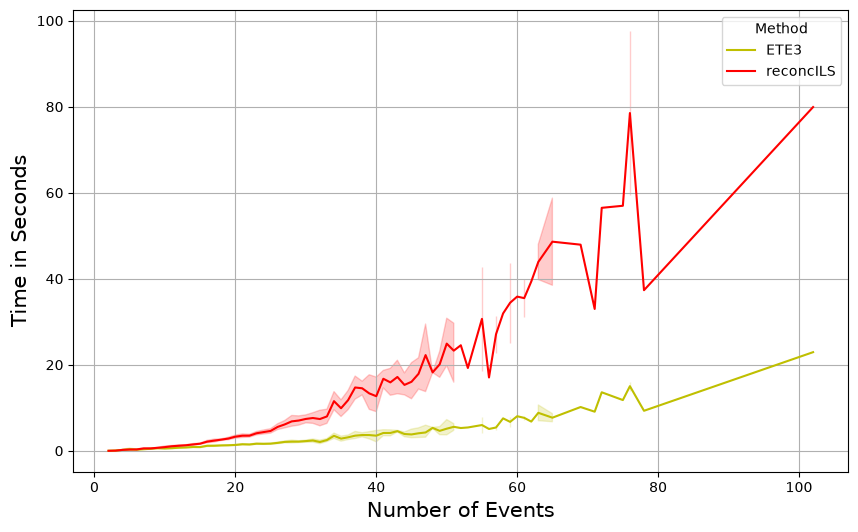

In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# File paths
#file1 = '/N/slate/samishr/reconcILS_03_18/reconcILS-main/reconcILS/example/Data_with_duplication_and_loss/Dupcoal_output_40_0.03_0.03/reconcILS_time_result.csv'
file1 = '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.03/reconcILS_time_result_1.1_1_1.csv'
#file2 = '/N/u/samishr/Quartz/Desktop/reconcILS_03_18/reconcILS-main/reconcILS/example/Data_with_duplication_and_loss/simphy_1_3_lb_1/_11_time_result.csv'
#result1 = '/N/slate/samishr/reconcILS_03_18/reconcILS-main/reconcILS/example/Data_with_duplication_and_loss/Dupcoal_output_40_0.03_0.03/reconcILS_result.csv'
#result2 = '/N/u/samishr/Quartz/Desktop/reconcILS_03_18/reconcILS-main/reconcILS/example/Data_with_duplication_and_loss/simphy_1_3_lb_1/_simphy_11_result.csv'
result1 = '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.03/reconcILS_result_1.1_1_1.csv'
# Load datasets
df_time1 = pd.read_csv(file1)
#df_time2 = pd.read_csv(file2)
df_result1 = pd.read_csv(result1)
#df_result2 = pd.read_csv(result2)

# Function to extract event sums for ETE3 and reconcILS
def extract_event_sums(df, method):
    filtered = df[df["Process"] == method]
    return filtered[['Duplication', 'Loss', 'NNI']].sum(axis=1).tolist()

# Add Event column for both methods in both datasets
df_time1_ete = df_time1.copy()
df_time1_reconc = df_time1.copy()
#df_time2_ete = df_time2.copy()
#df_time2_reconc = df_time2.copy()

df_time1_ete['Event'] = extract_event_sums(df_result1, 'True Process')
df_time1_reconc['Event'] = extract_event_sums(df_result1, 'True Process')
#df_time2_ete['Event'] = extract_event_sums(df_result2, 'True Simphy')
#df_time2_reconc['Event'] = extract_event_sums(df_result2, 'True Simphy')

# Add method labels
df_time1_ete['Method'] = 'ETE3'
df_time1_reconc['Method'] = 'reconcILS'
#df_time2_ete['Method'] = 'ETE3'
#df_time2_reconc['Method'] = 'reconcILS'

# All are 40 species now
#for df in [df_time1_ete, df_time1_reconc, df_time2_ete, df_time2_reconc]:
for df in [df_time1_ete, df_time1_reconc]:    
    df['Species'] = '40_species'

# Combine all
#combined_df = pd.concat([df_time1_ete, df_time1_reconc, df_time2_ete, df_time2_reconc], ignore_index=True)
combined_df = pd.concat([df_time1_ete, df_time1_reconc], ignore_index=True)
print(combined_df.describe())
# Rename columns
combined_df.rename(columns={'reconcILSTime_iterative': 'reconcILS Time', 'ete_time': 'ETE Time'}, inplace=True)

# Set appropriate time column based on method
combined_df['Time'] = combined_df.apply(lambda row: row['reconcILS Time'] if row['Method'] == 'reconcILS' else row['ETE Time'], axis=1)

# Plot lineplot (no markers)
plt.figure(figsize=(10, 6))
sns.lineplot(data=combined_df, x='Event', y='Time', hue='Method',palette=['y', 'r'])
plt.xlabel('Number of Events',fontsize=15.1)
plt.ylabel('Time in Seconds',fontsize=15.1)
#plt.title('Line Plot of Time vs Number of Events')
plt.grid(True)
plt.legend(title='Method')
plt.savefig('/N/u/samishr/Quartz/Time_plot.jpg', dpi=500)
plt.show()


/tmp/ipykernel_933110/29868339.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Variable', y='Value', data=df_combined, palette=['r', 'y'])
/tmp/ipykernel_933110/29868339.py:19: UserWarning: 
The palette list has fewer values (2) than needed (4) and will cycle, which may produce an uninterpretable plot.
  sns.boxplot(x='Variable', y='Value', data=df_combined, palette=['r', 'y'])


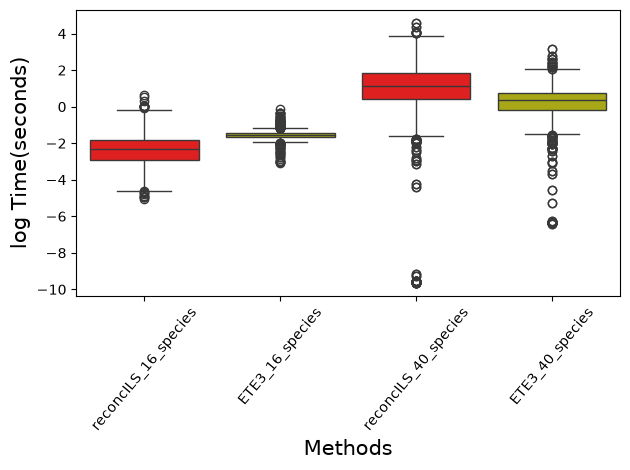

In [10]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

df =pd.read_csv('/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication__fungi_1_0_1_0.0015_0.003/_1_time_1.1_1_1.csv')
df_1= df[['reconcILSTime_iterative','ete_time']]
df_1=np.log(df_1)
df_1= df_1.rename(columns={'reconcILSTime_iterative': 'reconcILS_16_species', 'ete_time': 'ETE3_16_species'})
df_melted_1 = pd.melt(df_1, var_name='Variable', value_name='Value')
#sns.boxplot(x='Variable', y='Value', data=df_melted)
df_2 =combined_df[['reconcILS Time','ETE Time']]
df_2= df_2.rename(columns={'reconcILS Time': 'reconcILS_40_species', 'ETE Time': 'ETE3_40_species'})
df_2=np.log(df_2)
df_melted_2 = pd.melt(df_2, var_name='Variable', value_name='Value')

df_combined =pd.concat([df_melted_1,df_melted_2])
#df_combined =np.lo
sns.boxplot(x='Variable', y='Value', data=df_combined, palette=['r', 'y'])


plt.xlabel("Methods",fontsize=15.1)
plt.ylabel("log Time(seconds)",fontsize=15.1)
plt.xticks(rotation=50)
#plt.xlim(100, 100)
#plt.ylim(0, 0)
plt.tight_layout()
plt.savefig('/N/u/samishr/Quartz/Time_boxplot.jpg', dpi=500)


In [18]:
df =pd.read_csv('/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication__fungi_1_0_1_0.0015_0.003/_1_time_1.1_1_1.csv').mean()
df

reconcILSTime_iterative    0.141937
ete_time                   0.224816
dlcpar_time                3.308796
dtype: float64

       reconcILS_mem      ete_mem        Event
count    2000.000000  2000.000000  2000.000000
mean       33.216797     1.923249    22.694000
std        22.283278     0.966882    12.375902
min         0.114104     0.035471     2.000000
25%        19.115657     1.374217    15.000000
50%        30.576912     1.819679    21.000000
75%        38.454676     2.282742    28.000000
max       173.248419     8.269140   102.000000


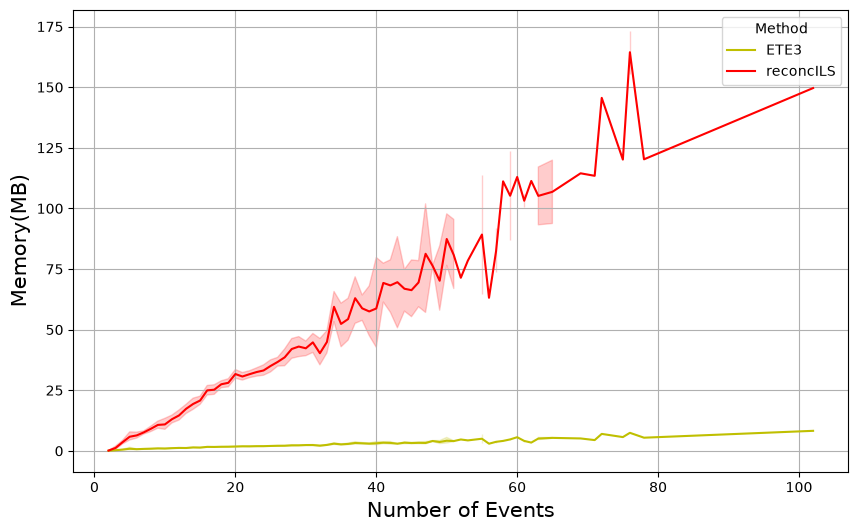

In [13]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# File paths
#file1 = '/N/u/samishr/Quartz/Desktop/reconcILS_03_18/reconcILS-main/reconcILS/example/Data_with_duplication_and_loss/Dupcoal_output_40_0.03_0.03/reconcILS_time_result.csv'
#file2 = '/N/u/samishr/Quartz/Desktop/reconcILS_03_18/reconcILS-main/reconcILS/example/Data_with_duplication_and_loss/simphy_1_3_lb_1/_11_time_result.csv'

#file1 = '/N/slate/samishr/reconcILS_03_18/reconcILS-main/reconcILS/example/Data_with_duplication_and_loss/Dupcoal_output_40_0.03_0.03/reconcILS_memory_result_with_dups_loss.csv'
file1= '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.03/reconcILS_memory_result_with_dups_loss_1.1_1_1.csv'
#file2 = '/N/u/samishr/Quartz/Desktop/reconcILS_03_18/reconcILS-main/reconcILS/example/Data_with_duplication_and_loss/simphy_1_3_lb_1/_1memory_result_with_dups_loss.csv'


result1 = '/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.03/reconcILS_result_1.1_1_1.csv'
#result2 = '/N/u/samishr/Quartz/Desktop/reconcILS_03_18/reconcILS-main/reconcILS/example/Data_with_duplication_and_loss/simphy_1_3_lb_1/_simphy_11_result.csv'

# Load datasets
df_time1 = pd.read_csv(file1)
#df_time2 = pd.read_csv(file2)
df_result1 = pd.read_csv(result1)
#df_result2 = pd.read_csv(result2)

# Function to extract event sums for ETE3 and reconcILS
def extract_event_sums(df, method):
    filtered = df[df["Process"] == method]
    return filtered[['Duplication', 'Loss', 'NNI']].sum(axis=1).tolist()


df_time1_ete = df_time1.copy()
df_time1_reconc = df_time1.copy()
#df_time2_ete = df_time2.copy()
#df_time2_reconc = df_time2.copy()

df_time1_ete['Event'] = extract_event_sums(df_result1, 'True Process')
df_time1_reconc['Event'] = extract_event_sums(df_result1, 'True Process')
#df_time2_ete['Event'] = extract_event_sums(df_result2, 'True Simphy')
#df_time2_reconc['Event'] = extract_event_sums(df_result2, 'True Simphy')

# Add method labels
df_time1_ete['Method'] = 'ETE3'
df_time1_reconc['Method'] = 'reconcILS'
#df_time2_ete['Method'] = 'ETE3'
#df_time2_reconc['Method'] = 'reconcILS'

# All are 40 species now
#for df in [df_time1_ete, df_time1_reconc, df_time2_ete, df_time2_reconc]:
for df in [df_time1_ete, df_time1_reconc]:
    df['Species'] = '40_species'

# Combine all
#combined_df = pd.concat([df_time1_ete, df_time1_reconc, df_time2_ete, df_time2_reconc], ignore_index=True)
combined_df = pd.concat([df_time1_ete, df_time1_reconc], ignore_index=True)
print(combined_df.describe())
# Rename columns
#reconcILS_mem,ete_mem
combined_df.rename(columns={'reconcILSTime_iterative': 'reconcILS_mem', 'ete_time': 'ete_mem'}, inplace=True)

# Set appropriate time column based on method
combined_df['Memory(MB)'] = combined_df.apply(lambda row: row['reconcILS_mem'] if row['Method'] == 'reconcILS' else row['ete_mem'], axis=1)

# Plot lineplot (no markers)
plt.figure(figsize=(10, 6))
sns.lineplot(data=combined_df, x='Event', y='Memory(MB)', hue='Method', palette=['y', 'r'])
plt.xlabel('Number of Events',fontsize=15.1)
plt.ylabel('Memory(MB)',fontsize=15.1)
#plt.title('Line Plot of Memory(MB) vs Number of Events')
plt.grid(True)
plt.legend(title='Method')
plt.savefig('/N/u/samishr/Quartz/Memory.jpg', dpi=500)
plt.show()


In [8]:
combined_df

,reconcILS_mem,ete_mem,Event,Method,Species,Memory(MB)
0,20.670532,3.640932,29,ETE3,40_species,3.640932
1,11.326141,2.076095,19,ETE3,40_species,2.076095
2,19.016998,5.268119,39,ETE3,40_species,5.268119
3,23.309389,3.689330,38,ETE3,40_species,3.689330
4,16.109469,2.980985,24,ETE3,40_species,2.980985
...,...,...,...,...,...,...
1995,12.691965,2.123379,32,reconcILS,40_species,12.691965
1996,13.665537,1.578286,17,reconcILS,40_species,13.665537
1997,18.204935,2.537111,30,reconcILS,40_species,18.204935
1998,36.758894,7.138851,53,reconcILS,40_species,36.758894


/tmp/ipykernel_933110/1534092834.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Variable', y='Value', data=df_combined, palette=['r', 'y'])
/tmp/ipykernel_933110/1534092834.py:17: UserWarning: 
The palette list has fewer values (2) than needed (4) and will cycle, which may produce an uninterpretable plot.
  sns.boxplot(x='Variable', y='Value', data=df_combined, palette=['r', 'y'])


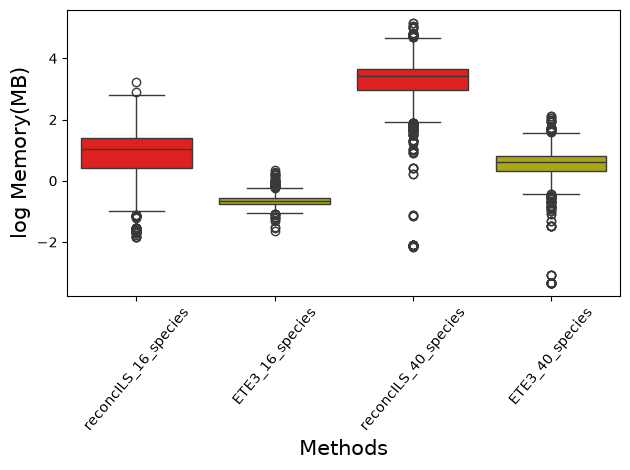

In [24]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df =pd.read_csv('/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication__fungi_1_0_1_0.0015_0.003/_1_mem_1.1_1_1.csv')
df_1= df[['reconcILSMEM_iterative','ete_mem']]
df_1= df_1.rename(columns={'reconcILSMEM_iterative': 'reconcILS_16_species', 'ete_mem': 'ETE3_16_species'})
df_1= np.log(df_1)
df_melted_1 = pd.melt(df_1, var_name='Variable', value_name='Value')
#sns.boxplot(x='Variable', y='Value', data=df_melted)
df_2 =combined_df[['reconcILS_mem','ete_mem']]
df_2= df_2.rename(columns={'reconcILS_mem': 'reconcILS_40_species', 'ete_mem': 'ETE3_40_species'})
df_2= np.log(df_2)
df_melted_2 = pd.melt(df_2, var_name='Variable', value_name='Value')

df_combined =pd.concat([df_melted_1,df_melted_2])
sns.boxplot(x='Variable', y='Value', data=df_combined, palette=['r', 'y'])


plt.xlabel("Methods",fontsize=15.1)
plt.ylabel("log Memory(MB)",fontsize=15.1)
plt.xticks(rotation=50)
plt.tight_layout()
plt.savefig('/N/u/samishr/Quartz/Memory_boxplot.jpg', dpi=500)



In [14]:
#df =pd.read_csv('/N/slate/samishr/reconcILS_03_18/reconcILS-main/reconcILS/example/Data_with_duplication_and_loss/Data_with_duplication_3_0.03_0.03/_1_mem.csv')
df

,reconcILSTime_iterative,ete_time
0,0.186381,0.122154
1,0.051110,0.078136
2,0.042206,0.068008
3,0.201206,0.116384
4,0.035854,0.064808
...,...,...
995,0.151768,0.073288
996,0.198873,0.083120
997,0.254581,0.123464
998,0.062582,0.084904


In [22]:
df =pd.read_csv('/N/slate/samishr/reconcILS_03_18/EXPERIMENT_6/reconcILS/experiments/Data_with_duplication_40_species_0.03_0.03/reconcILS_time_result_1.1_1_1.csv').mean()
df

reconcILSTime_iterative    5.707649
ete_time                   1.794245
dtype: float64

In [2]:
import sys
import os
sys.path.append("../")
sys.path.append("../../")
from reconcILS import *
from utils_reconcILS import *
import shutil



red= readWrite.readWrite()
dupcoal_o = open('/N/u/samishr/Quartz/Desktop/reconcILS_03_18/reconcILS-main/reconcILS/example/Dupcoal_40_Just_ILS/trees.tre')
gene_trees= dupcoal_o.read().split('\n')
simphy_o = open('/N/u/samishr/Quartz/Desktop/reconcILS_03_18/reconcILS-main/reconcILS/example/simphy_40_Just_ILS/g_trees.tre')
simphy_r =simphy_o.read().split('\n')




with open('/N/u/samishr/Quartz/Desktop/reconcILS_03_18/reconcILS-main/reconcILS/example/bin/dupcoal.txt', 'w') as f:
    for tree in gene_trees[:-1]:
        tree= tree.replace('e-', '0')
        #red.parse(tree)
        
        f.write(f"{red.parse(tree).to_newick()}\n")

gene_trees = simphy_r       
with open('/N/u/samishr/Quartz/Desktop/reconcILS_03_18/reconcILS-main/reconcILS/example/bin/simphy.txt', 'w') as f:
    for tree in gene_trees[:-1]:
        tree= tree.replace('e-', '0')
        #red.parse(tree)
        f.write(f"{red.parse(tree).to_newick()}\n")
        
        

os.chdir('./bin')
os.system('./iqtree3 -t concat.treefile --gcf dupcoal.txt --prefix concord')

shutil.move('./concord.cf.branch', './dupcoal_iq/concord.cf.branch')
shutil.move('./concord.cf.stat', './dupcoal_iq/concord.cf.stat')
shutil.move('./concord.cf.tree', './dupcoal_iq/concord.cf.tree')
shutil.move('./concord.cf.tree.nex', './dupcoal_iq/concord.cf.tree.nex')
shutil.move('./concord.log', './dupcoal_iq/concord.log')




os.system('./iqtree3 -t concat.treefile --gcf simphy.txt --prefix concord')



shutil.move('./concord.cf.branch', './simphy_iq/concord.cf.branch')
shutil.move('./concord.cf.stat', './simphy_iq/concord.cf.stat')
shutil.move('./concord.cf.tree', './simphy_iq/concord.cf.tree')
shutil.move('./concord.cf.tree.nex', './simphy_iq/concord.cf.tree.nex')
shutil.move('./concord.log', './simphy_iq/concord.log')
os.chdir('..')





IQ-TREE version 3.0.1 for Linux x86 64-bit built May  5 2025
Developed by Bui Quang Minh, Thomas Wong, Nhan Ly-Trong, Huaiyan Ren
Contributed by Lam-Tung Nguyen, Dominik Schrempf, Chris Bielow,
Olga Chernomor, Michael Woodhams, Diep Thi Hoang, Heiko Schmidt

Host:    i54.red.uits.iu.edu (AVX2, FMA3, 345 GB RAM)
Command: /geode2/home/u080/samishr/Quartz/Desktop/reconcILS_03_18/reconcILS-main/reconcILS/example/bin/iqtree3_intel -t concat.treefile --gcf dupcoal.txt --prefix concord
Seed:    368892 (Using SPRNG - Scalable Parallel Random Number Generator)
Time:    Fri Jun 27 14:04:14 2025
Kernel:  AVX+FMA - 1 threads (44 CPU cores detected)

HINT: Use -nt option to specify number of threads because your CPU has 44 cores!
HINT: -nt AUTO will automatically determine the best number of threads to use.

Reading tree concat.treefile ...
rooted tree with 40 taxa and 79 branches
Reading tree(s) file dupcoal.txt ...
1000 tree(s) loaded (1000 rooted and 0 unrooted)
Computing gene concordance factor

"\nos.system('./iqtree3 -t concat.treefile --gcf simphy.txt --prefix concord')\n\n\n\nshutil.move('./concord.cf.branch', './simphy_iq/concord.cf.branch')\nshutil.move('./concord.cf.stat', './simphy_iq/concord.cf.stat')\nshutil.move('./concord.cf.tree', './simphy_iq/concord.cf.tree')\nshutil.move('./concord.cf.tree.nex', './simphy_iq/concord.cf.tree.nex')\nshutil.move('./concord.log', './simphy_iq/concord.log')\nos.chdir('..')\n\n"

In [839]:
import pandas as pd
df =pd.read_csv('/N/u/samishr/Quartz/Desktop/reconcILS_03_18/reconcILS-main/reconcILS/example/Dupcoal_40_Just_ILS/reconcILS_result.csv')
df[df["Process"] == 'ETE3'].describe()

,Replicate,Duplication,NNI,DLCILS,Loss,Hemiplasy,RHemiplasy
count,1000.000000,1000.000000,1000.0,1000.0,1000.000000,1000.0,1000.0
mean,499.500000,9.490000,0.0,0.0,34.394000,0.0,0.0
std,288.819436,1.943625,0.0,0.0,6.727855,0.0,0.0
min,0.000000,3.000000,0.0,0.0,13.000000,0.0,0.0
25%,249.750000,8.000000,0.0,0.0,30.000000,0.0,0.0
50%,499.500000,9.000000,0.0,0.0,34.000000,0.0,0.0
75%,749.250000,11.000000,0.0,0.0,39.000000,0.0,0.0
max,999.000000,16.000000,0.0,0.0,54.000000,0.0,0.0


In [837]:
df

,Process,Replicate,Gene_tree,Species_Tree,Duplication,NNI,DLCILS,Loss,Hemiplasy,RHemiplasy
0,True Process,0,"(((((((R_1:0.31108979569727047,E_1:0.311089795...","((((M,(AF,B)),(P,(AJ,(AE,(O,D))))),((W,AH),((A...",0,20,1,0,0,0
1,ETE3,0,"(((((AB,Y),H),(L,((Z,(C,(K,F))),((A,AC),V)))),...","((((M,(AF,B)),(P,(AJ,(AE,(O,D))))),((W,AH),((A...",12,0,0,47,0,0
2,reconcILS,0,"(((((AB_1,Y_1),H_1),(L_1,((Z_1,(C_1,(K_1,F_1))...","((((0-0-0 0-0-1 M,(0-0-0 0-0-1 AF,0-0-...",0,23,0,0,0,0
3,True Process,1,"(((((AC_1:0.25915232052489295,A_1:0.2591523205...","((((M,(AF,B)),(P,(AJ,(AE,(O,D))))),((W,AH),((A...",0,13,1,0,0,0
4,ETE3,1,"((((N,AN),((AF,((AE,D),(AJ,(P,O)))),(M,B))),((...","((((M,(AF,B)),(P,(AJ,(AE,(O,D))))),((W,AH),((A...",9,0,0,32,0,0
...,...,...,...,...,...,...,...,...,...,...
2995,ETE3,998,"(((((V,((AC,A),L)),((Z,C),(K,F))),((AM,(((U,AL...","((((M,(AF,B)),(P,(AJ,(AE,(O,D))))),((W,AH),((A...",8,0,0,25,0,0
2996,reconcILS,998,"(((((V_1,((AC_1,A_1),L_1)1I L_1),((Z_1,C_1),(...","((((0-0-0 0-0-1 M,(0-0-0 0-0-1 AF,0-0-...",0,9,0,0,0,0
2997,True Process,999,"((O_1:5.196563658374043,((((B_1:0.671099243106...","((((M,(AF,B)),(P,(AJ,(AE,(O,D))))),((W,AH),((A...",0,14,1,0,0,0
2998,ETE3,999,"((((((AD,(G,S)),((J,(I,AK)),Q)),((AL,(T,(U,AI)...","((((M,(AF,B)),(P,(AJ,(AE,(O,D))))),((W,AH),((A...",8,0,0,30,0,0


In [821]:
df[df["Process"] == 'reconcILS'].describe()

,Replicate,Duplication,NNI,DLCILS,Loss,Hemiplasy,RHemiplasy
count,1000.000000,1000.0,1000.000000,1000.0,1000.0,1000.0,1000.0
mean,499.500000,0.0,15.839000,0.0,0.0,0.0,0.0
std,288.819436,0.0,3.672406,0.0,0.0,0.0,0.0
min,0.000000,0.0,6.000000,0.0,0.0,0.0,0.0
25%,249.750000,0.0,13.000000,0.0,0.0,0.0,0.0
50%,499.500000,0.0,16.000000,0.0,0.0,0.0,0.0
75%,749.250000,0.0,18.000000,0.0,0.0,0.0,0.0
max,999.000000,0.0,28.000000,0.0,0.0,0.0,0.0


# Function to get stats 

In [6]:
def give_me_results(df,flag):
    #df= df.dropna()

    #df=df[df.Gene_tree!='None;']
    cols = [flag]
    true_dup_loss = (df.loc[df['Process'].eq('True Process'), cols]
              .reset_index(drop=True))
    ete3  = (df.loc[df['Process'].eq('ETE3'), cols]
              .reset_index(drop=True))
    
    
    l2_diff_ete3 = np.linalg.norm(true_dup_loss.to_numpy() - ete3.to_numpy(), axis=1)
    l2_series_ete3 = pd.Series(l2_diff_ete3, name='L2_Diff')
    #print("ETE3 Mean L2 distance:", l2_series_ete3.mean())


    cols = [flag]
    true_dup_loss_nni = (df.loc[df['Process'].eq('True Process'), cols]
              .reset_index(drop=True))
    reconcILS  = (df.loc[df['Process'].eq('reconcILS'), cols]
              .reset_index(drop=True))

    print(true_dup_loss_nni)
    print(reconcILS)
    l2_diff_reconcILS = np.linalg.norm(true_dup_loss_nni.to_numpy() - reconcILS.to_numpy(), axis=1)
    l2_series_reconcILS = pd.Series(l2_diff_reconcILS, name='L2_Diff')



    #print("reconcILS Mean L2 distance:", l2_series_reconcILS.mean())
    if flag=='NNI':
        return 0,l2_series_reconcILS.mean()
    else:
        return l2_series_ete3.mean(),l2_series_reconcILS.mean()
        

    '''
    cols = ['Duplication', 'Loss','DLCILS']
    true_dup_loss_dlcils = (df.loc[df['Process'].eq('True Process'), cols]
              .reset_index(drop=True))
    DLCpar  = (df.loc[df['Process'].eq('DLCpar'), cols]
              .reset_index(drop=True))

    l2_diff_dlcpar = np.linalg.norm(true_dup_loss_dlcils.to_numpy() - DLCpar.to_numpy(), axis=1)
    l2_series_dlcpar = pd.Series(l2_diff_dlcpar, name='L2_Diff')



    print("DLCpar Mean L2 distance:", l2_series_dlcpar.mean())
    '''


# Extract all results

In [21]:
data_location='./Data_with_duplication_and_loss/'

df_med_0=pd.read_csv(data_location+'Data_with_duplication_40_species_5k_0.0003_0.0003_1/reconcILS_resulttrees.tre.csv')
df_med_0_list =df_med_0[df_med_0.Process == 'True Process']['Gene_tree'].to_numpy()

df_med_1=pd.read_csv(data_location+'Data_with_duplication_40_species_5k_0.0003_0.0003_1/reconcILS_resulterror_trees_5.tre.csv')
df_med_1_list =df_med_1[df_med_1.Process == 'True Process']['Gene_tree'].to_numpy()

df_med_2=pd.read_csv(data_location+'Data_with_duplication_40_species_5k_0.0003_0.0003_1/reconcILS_resulterror_trees_10.tre.csv')
df_med_2_list =df_med_2[df_med_2.Process == 'True Process']['Gene_tree'].to_numpy()

df_med_3=pd.read_csv(data_location+'Data_with_duplication_40_species_5k_0.0003_0.0003_1/reconcILS_resulterror_trees_15.tre.csv')
df_med_3_list =df_med_3[df_med_3.Process == 'True Process']['Gene_tree'].to_numpy()



df_med_4=pd.read_csv(data_location+'Data_with_duplication_40_species_2k_0.0003_0.0003/reconcILS_resulttrees.tre.csv')
df_med_4_list =df_med_4[df_med_4.Process == 'True Process']['Gene_tree'].to_numpy()

df_med_5=pd.read_csv(data_location+'Data_with_duplication_40_species_2k_0.0003_0.0003/reconcILS_resulterror_trees_5.tre.csv')
df_med_5_list =df_med_5[df_med_5.Process == 'True Process']['Gene_tree'].to_numpy()

df_med_6=pd.read_csv(data_location+'Data_with_duplication_40_species_2k_0.0003_0.0003/reconcILS_resulterror_trees_10.tre.csv')
df_med_6_list =df_med_6[df_med_6.Process == 'True Process']['Gene_tree'].to_numpy()

df_med_7=pd.read_csv(data_location+'Data_with_duplication_40_species_2k_0.0003_0.0003/reconcILS_resulterror_trees_15.tre.csv')
df_med_7_list =df_med_7[df_med_7.Process == 'True Process']['Gene_tree'].to_numpy()



df_med_8=pd.read_csv(data_location+'Dupcoal_output_40_0.03_0.03/reconcILS_result.csv')
df_med_8_list =df_med_8[df_med_8.Process == 'True Process']['Gene_tree'].to_numpy()

df_med_9=pd.read_csv(data_location+'Dupcoal_output_40_0.03_0.03/reconcILS_result_error_5.csv')
df_med_9_list =df_med_9[df_med_9.Process == 'True Process']['Gene_tree'].to_numpy()

df_med_10=pd.read_csv(data_location+'Dupcoal_output_40_0.03_0.03/reconcILS_result_error_10.csv')
df_med_10_list =df_med_10[df_med_10.Process == 'True Process']['Gene_tree'].to_numpy()

df_med_11=pd.read_csv(data_location+'Dupcoal_output_40_0.03_0.03/reconcILS_result_error_15.csv')
df_med_11_list =df_med_11[df_med_11.Process == 'True Process']['Gene_tree'].to_numpy()


In [22]:
dic={'Medium_No_error':df_med_4,'Medium_5_error':df_med_5,
        'Medium_10_error':df_med_6,'Medium_15_error':df_med_7,
     'High_No_error':df_med_0,'High_5_error':df_med_1,
        'High_10_error':df_med_2,'High_15_error':df_med_3,
     'Normal_No_error':df_med_8,'Normal_5_error':df_med_9,
        'Normal_10_error':df_med_10,'Normal_15_error':df_med_11,
        }

dic_label = {'Medium':[0.0003,'x200'],'High':[0.0003,'x500'],'Normal':[0.003,'x1']}



In [23]:
result={'Dataset':[],'branch_scale':[],'dup_loss_rate':[],
        'True_process_average_Duplication':[],
        'True_process_average_NNI':[],
        'True_process_average_Loss':[]
        ,'reconcILS_Duplication_pearson':[],'reconcILS_Loss_pearson':[],'reconcILS_NNI_pearson':[],
       'reconcILS_Duplication_spearman':[],'reconcILS_Loss_spearman':[],'reconcILS_NNI_spearman':[],
               'reconcILS_Duplication_l2':[],'reconcILS_Loss_l2':[],'reconcILS_NNI_l2':[],
        'ETE3_Duplication_pearson':[],'ETE3_Loss_pearson':[],
       'ETE3_Duplication_spearman':[],'ETE3_Loss_spearman':[],
        'ETE3_Duplication_l2':[],'ETE3_Loss_l2':[],
        
       }

for label,df in dic.items():
    print(label)
    result['Dataset']+=[label]
    dup_loss_rate , branch_scale = dic_label[label.split('_')[0]][0],dic_label[label.split('_')[0]][1]
    result['branch_scale']+=[branch_scale]
    result['dup_loss_rate']+=[dup_loss_rate]
    
    
    subset = df[df.Process == 'True Process'][['Duplication','NNI','Loss']]
    desc = subset.describe()

    means = desc.loc['mean'].to_dict()
    stds = desc.loc['std'].to_dict()
    
    #print(means)
    result['True_process_average_Duplication']+=[means['Duplication']]
    result['True_process_average_NNI']+=[means['NNI']]
    result['True_process_average_Loss']+=[means['Loss']]
    
    flag_N_ete3=0
    flag_N_reconcILS=0
    
    flag_D_ete3=0
    flag_D_reconcILS=0
    
    flag_L_ete3=0
    flag_L_reconcILS=0
    rr ={'ETE3':{'NNI':0,'Duplication':0,'Loss':0},'reconcILS':{'NNI':0,'Duplication':0,'Loss':0}}
    
    for flag in ['Duplication','Loss','NNI']:
        v0,v1= give_me_results(df,flag)
        rr['ETE3'][flag]=v0
        rr['reconcILS'][flag]=v1
        
    result['reconcILS_Duplication_l2']+=[rr['reconcILS']['Duplication']]
    result['reconcILS_Loss_l2']+=[rr['reconcILS']['Loss']]
    result['reconcILS_NNI_l2']+=[rr['reconcILS']['NNI']]
            
    result['ETE3_Duplication_l2']+=[rr['ETE3']['Duplication']]
    result['ETE3_Loss_l2']+=[rr['ETE3']['Loss']]
    #result['ETE3_NNI_l2']+=[0]
    
        

    rho_reconcILS_loss_spearman,p_reconcILS_loss_spearman  = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['Loss']),columns=['Loss']),pd.DataFrame(list(df[(df.Process == "reconcILS")]['Loss']),columns=['Loss']))
    rho_reconcILS_dups_spearman, p_reconcILS_dups_spearman = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['Duplication']),columns=['dups']),pd.DataFrame(list(df[(df.Process == "reconcILS")]['Duplication']),columns=['dups']))
    rho_reconcILS_NNI_spearman, p_reconcILS_NNI_spearman = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['NNI']),columns=['NNI']),pd.DataFrame(list(df[(df.Process == "reconcILS")]['NNI']),columns=['NNI']))

    rho_reconcILS_loss_pearson, p_reconcILS_loss_pearson = pearsonr(df[df.Process == "True Process"]['Loss'],df[df.Process == "reconcILS"]['Loss'])
    rho_reconcILS_dups_pearson, p_reconcILS_dups_pearson = pearsonr(df[df.Process == "True Process"]['Duplication'],df[df.Process == "reconcILS"]['Duplication'])
    rho_reconcILS_NNI_pearson, p_reconcILS_NNI_pearson = pearsonr(df[df.Process == "True Process"]['NNI'],df[df.Process == "reconcILS"]['NNI'])


    print('Default cost')
    print('Pearson R reconcILS')
    print('reconcILS_Duplication:', rho_reconcILS_dups_pearson)
    print('reconcILS_Loss:', rho_reconcILS_loss_pearson)
    print('reconcILS_NNI:', rho_reconcILS_NNI_pearson)
    
    result['reconcILS_Duplication_pearson']+=[rho_reconcILS_dups_pearson]
    result['reconcILS_Loss_pearson']+=[rho_reconcILS_loss_pearson]
    result['reconcILS_NNI_pearson']+=[rho_reconcILS_NNI_pearson]

    print('Spearman R reconcILS')
    print('reconcILS_Duplication:',rho_reconcILS_dups_spearman)
    print('reconcILS_Loss:',rho_reconcILS_loss_spearman)
    print('reconcILS_NNI:',rho_reconcILS_NNI_spearman)
    
        
    result['reconcILS_Duplication_spearman']+=[rho_reconcILS_dups_spearman]
    result['reconcILS_Loss_spearman']+=[rho_reconcILS_loss_spearman]
    result['reconcILS_NNI_spearman']+=[rho_reconcILS_NNI_spearman]
    
    print('*'*140)
    rho_ete3_loss_spearman,p_ete3_loss_spearman  = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['Loss']),columns=['Loss']),pd.DataFrame(list(df[(df.Process == "ETE3")]['Loss']),columns=['Loss']))
    rho_ete3_dups_spearman, p_ete3_dups_spearman = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['Duplication']),columns=['dups']),pd.DataFrame(list(df[(df.Process == "ETE3")]['Duplication']),columns=['dups']))
    rho_ete3_NNI_spearman, p_ete3_NNI_spearman = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['NNI']),columns=['NNI']),pd.DataFrame(list(df[(df.Process == "ETE3")]['NNI']),columns=['NNI']))

    rho_ete3_loss_pearson, p_ete3_loss_pearson = pearsonr(df[df.Process == "True Process"]['Loss'],df[df.Process == "ETE3"]['Loss'])
    rho_ete3_dups_pearson, p_ete3_dups_pearson = pearsonr(df[df.Process == "True Process"]['Duplication'],df[df.Process == "ETE3"]['Duplication'])
    rho_ete3_NNI_pearson, p_ete3_NNI_pearson = pearsonr(df[df.Process == "True Process"]['NNI'],df[df.Process == "ETE3"]['NNI'])


    print('Pearson R ETE3')
    print('reconcILS_Duplication:', rho_ete3_dups_pearson)
    print('reconcILS_Loss:', rho_ete3_loss_pearson)
    print('reconcILS_NNI:', rho_ete3_NNI_pearson)
    
        
    result['ETE3_Duplication_pearson']+=[rho_ete3_dups_pearson]
    result['ETE3_Loss_pearson']+=[rho_ete3_loss_pearson]
    #result['ETE3_NNI_pearson']+=[rho_ete3_NNI_pearson]


    print('Spearman R ETE3')
    print('reconcILS_Duplication:',rho_ete3_dups_spearman)
    print('reconcILS_Loss:',rho_ete3_loss_spearman)
    print('reconcILS_NNI:',rho_ete3_NNI_spearman)
    
    result['ETE3_Duplication_spearman']+=[rho_ete3_dups_spearman]
    result['ETE3_Loss_spearman']+=[rho_ete3_loss_spearman]
    #result['ETE3_NNI_spearman']+=[rho_ete3_NNI_spearman]
    
    print('*'*140)
    print('\n')



Medium_No_error
     Duplication
0              5
1              3
2              0
3              1
4             15
..           ...
995            7
996            0
997            3
998            4
999            5

[1000 rows x 1 columns]
     Duplication
0              5
1              3
2              0
3              1
4             16
..           ...
995            7
996            0
997            3
998            4
999            5

[1000 rows x 1 columns]
     Loss
0       5
1       5
2       2
3       3
4       5
..    ...
995     2
996     2
997     6
998     5
999     3

[1000 rows x 1 columns]
     Loss
0       4
1       3
2       1
3       3
4       2
..    ...
995     2
996     1
997     2
998     5
999     3

[1000 rows x 1 columns]
     NNI
0      1
1      0
2      0
3      0
4      0
..   ...
995    1
996    0
997    0
998    0
999    1

[1000 rows x 1 columns]
     NNI
0      2
1      1
2      0
3      0
4      4
..   ...
995    1
996    0
997    3
998    0
999 

/usr/lib/python3/dist-packages/scipy/stats/_stats_py.py:4529: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/lib/python3/dist-packages/scipy/stats/_stats_py.py:4068: PearsonRConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(PearsonRConstantInputWarning())
/usr/lib/python3/dist-packages/scipy/stats/_stats_py.py:4529: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/lib/python3/dist-packages/scipy/stats/_stats_py.py:4068: PearsonRConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(PearsonRConstantInputWarning())
/usr/lib/python3/dist-packages/scipy/stats/_stats_py.py:4529: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficient

Default cost
Pearson R reconcILS
reconcILS_Duplication: 0.9938543733889976
reconcILS_Loss: 0.8667092261671074
reconcILS_NNI: 0.10354583851110977
Spearman R reconcILS
reconcILS_Duplication: 0.993484804399725
reconcILS_Loss: 0.8492027596207554
reconcILS_NNI: 0.07831457593142248
********************************************************************************************************************************************
Pearson R ETE3
reconcILS_Duplication: 0.9961534093575363
reconcILS_Loss: 0.9497595136562091
reconcILS_NNI: nan
Spearman R ETE3
reconcILS_Duplication: 0.9954263662543354
reconcILS_Loss: 0.9356826621846442
reconcILS_NNI: nan
********************************************************************************************************************************************


High_5_error
     Duplication
0             10
1             12
2             10
3             25
4              2
..           ...
995           11
996            5
997            4
998            0
999            7

/usr/lib/python3/dist-packages/scipy/stats/_stats_py.py:4529: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/lib/python3/dist-packages/scipy/stats/_stats_py.py:4068: PearsonRConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(PearsonRConstantInputWarning())
/usr/lib/python3/dist-packages/scipy/stats/_stats_py.py:4529: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/lib/python3/dist-packages/scipy/stats/_stats_py.py:4068: PearsonRConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(PearsonRConstantInputWarning())
/usr/lib/python3/dist-packages/scipy/stats/_stats_py.py:4529: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficient

     NNI
0     23
1     15
2     29
3     31
4     19
..   ...
995   25
996   14
997   24
998   40
999   23

[1000 rows x 1 columns]
     NNI
0     25
1     12
2     24
3     26
4     17
..   ...
995   13
996   13
997   19
998   35
999   25

[1000 rows x 1 columns]
Default cost
Pearson R reconcILS
reconcILS_Duplication: 0.9258544299404751
reconcILS_Loss: 0.5249288666333547
reconcILS_NNI: 0.6759814223631966
Spearman R reconcILS
reconcILS_Duplication: 0.9357124997545446
reconcILS_Loss: 0.5826294283837953
reconcILS_NNI: 0.605579266130789
********************************************************************************************************************************************
Pearson R ETE3
reconcILS_Duplication: 0.7924441946758466
reconcILS_Loss: 0.367028287746539
reconcILS_NNI: nan
Spearman R ETE3
reconcILS_Duplication: 0.7401396765628148
reconcILS_Loss: 0.2294948500665607
reconcILS_NNI: nan
************************************************************************************************

/usr/lib/python3/dist-packages/scipy/stats/_stats_py.py:4529: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/lib/python3/dist-packages/scipy/stats/_stats_py.py:4068: PearsonRConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(PearsonRConstantInputWarning())
/usr/lib/python3/dist-packages/scipy/stats/_stats_py.py:4529: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/lib/python3/dist-packages/scipy/stats/_stats_py.py:4068: PearsonRConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(PearsonRConstantInputWarning())


# Snapshot of results

In [24]:
pd.DataFrame(result).to_csv('results_reconcILS_error.csv',index=False)
pd.DataFrame(result)

,Dataset,branch_scale,dup_loss_rate,True_process_average_Duplication,True_process_average_NNI,True_process_average_Loss,reconcILS_Duplication_pearson,reconcILS_Loss_pearson,reconcILS_NNI_pearson,reconcILS_Duplication_spearman,...,reconcILS_NNI_spearman,reconcILS_Duplication_l2,reconcILS_Loss_l2,reconcILS_NNI_l2,ETE3_Duplication_pearson,ETE3_Loss_pearson,ETE3_Duplication_spearman,ETE3_Loss_spearman,ETE3_Duplication_l2,ETE3_Loss_l2
0,Medium_No_error,x200,0.0003,3.398,0.071,3.521,0.981463,0.717849,0.076866,0.983064,...,0.162538,0.266,1.168,1.096,0.991033,0.860751,0.990314,0.814101,0.172,1.112
1,Medium_5_error,x200,0.0003,3.398,0.071,3.521,0.965060,0.422101,0.053709,0.954673,...,0.066688,0.470,1.340,5.881,0.734938,0.180597,0.689532,0.174820,4.180,13.566
2,Medium_10_error,x200,0.0003,3.398,0.071,3.521,0.891885,0.070640,0.107318,0.867996,...,0.112188,0.960,2.793,10.172,0.663161,0.129369,0.663675,0.155218,7.907,27.545
3,Medium_15_error,x200,0.0003,3.398,0.071,3.521,0.756849,0.037648,0.057363,0.760346,...,0.050104,1.895,6.425,13.232,0.622716,0.136827,0.643473,0.146244,10.957,40.723
4,High_No_error,x500,0.0003,7.664,0.126,9.196,0.993854,0.866709,0.103546,0.993485,...,0.078315,0.618,5.173,3.187,0.996153,0.949760,0.995426,0.935683,0.672,4.005
5,High_5_error,x500,0.0003,7.664,0.126,9.196,0.991172,0.739225,0.079509,0.987874,...,0.067196,0.729,5.064,6.568,0.956106,0.597225,0.950756,0.685014,2.558,8.257
6,High_10_error,x500,0.0003,7.664,0.126,9.196,0.983832,0.439697,0.094365,0.977362,...,0.076410,1.021,5.294,9.266,0.926216,0.549697,0.944235,0.675968,4.899,17.125
7,High_15_error,x500,0.0003,7.664,0.126,9.196,0.965951,0.215212,0.050400,0.960206,...,0.045708,1.546,6.823,11.382,0.900111,0.518293,0.944651,0.670006,7.026,25.781
8,Normal_No_error,x1,0.0030,2.844,25.682,3.080,0.938963,0.622710,0.721970,0.950814,...,0.669178,0.601,1.400,7.839,0.832747,0.385112,0.794560,0.226492,8.686,34.982
9,Normal_5_error,x1,0.0030,2.844,25.682,3.080,0.925854,0.524929,0.675981,0.935712,...,0.605579,0.726,1.821,6.736,0.792444,0.367028,0.740140,0.229495,10.914,43.749


# Extract results on 16 species data

In [25]:
df=pd.read_csv('./Data_with_duplication_and_loss/Data_with_duplication__fungi_1_0_1_0.015_0.03/_1_result.csv')
#df= pd.read_csv("/N/slate/samishr/reconcILS_03_18/reconcILS-main/reconcILS/example/Experiments/Data_with_duplication_and_loss/Data_with_duplication_40_species_100_0.005_0.02/reconcILS_resulttrees.tre.csv")
from scipy.stats import spearmanr,pearsonr

rho_reconcILS_loss_spearman,p_reconcILS_loss_spearman  = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['Loss']),columns=['Loss']),pd.DataFrame(list(df[(df.Process == "reconcILS")]['Loss']),columns=['Loss']))
rho_reconcILS_dups_spearman, p_reconcILS_dups_spearman = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['Duplication']),columns=['dups']),pd.DataFrame(list(df[(df.Process == "reconcILS")]['Duplication']),columns=['dups']))
rho_reconcILS_NNI_spearman, p_reconcILS_NNI_spearman = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['NNI']),columns=['NNI']),pd.DataFrame(list(df[(df.Process == "reconcILS")]['NNI']),columns=['NNI']))

rho_reconcILS_loss_pearson, p_reconcILS_loss_pearson = pearsonr(df[df.Process == "True Process"]['Loss'],df[df.Process == "reconcILS"]['Loss'])
rho_reconcILS_dups_pearson, p_reconcILS_dups_pearson = pearsonr(df[df.Process == "True Process"]['Duplication'],df[df.Process == "reconcILS"]['Duplication'])
rho_reconcILS_NNI_pearson, p_reconcILS_NNI_pearson = pearsonr(df[df.Process == "True Process"]['NNI'],df[df.Process == "reconcILS"]['NNI'])


print('Default cost')
print('Pearson R reconcILS')
print('reconcILS_Duplication:', rho_reconcILS_dups_pearson)
print('reconcILS_Loss:', rho_reconcILS_loss_pearson)
print('reconcILS_NNI:', rho_reconcILS_NNI_pearson)


print('Spearman R reconcILS')
print('reconcILS_Duplication:',rho_reconcILS_dups_spearman)
print('reconcILS_Loss:',rho_reconcILS_loss_spearman)
print('reconcILS_NNI:',rho_reconcILS_NNI_spearman)




rho_ete3_loss_spearman,p_ete3_loss_spearman  = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['Loss']),columns=['Loss']),pd.DataFrame(list(df[(df.Process == "DLCpar")]['Loss']),columns=['Loss']))
rho_ete3_dups_spearman, p_ete3_dups_spearman = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['Duplication']),columns=['dups']),pd.DataFrame(list(df[(df.Process == "DLCpar")]['Duplication']),columns=['dups']))
rho_ete3_NNI_spearman, p_ete3_NNI_spearman = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['NNI']),columns=['NNI']),pd.DataFrame(list(df[(df.Process == "DLCpar")]['DLCILS']),columns=['NNI']))

rho_ete3_loss_pearson, p_ete3_loss_pearson = pearsonr(df[df.Process == "True Process"]['Loss'],df[df.Process == "DLCpar"]['Loss'])
rho_ete3_dups_pearson, p_ete3_dups_pearson = pearsonr(df[df.Process == "True Process"]['Duplication'],df[df.Process == "DLCpar"]['Duplication'])
rho_ete3_NNI_pearson, p_ete3_NNI_pearson = pearsonr(df[df.Process == "True Process"]['NNI'],df[df.Process == "DLCpar"]['DLCILS'])


print('Pearson R DLCPAR')
print('reconcILS_Duplication:', rho_ete3_dups_pearson)
print('reconcILS_Loss:', rho_ete3_loss_pearson)
print('reconcILS_NNI:', rho_ete3_NNI_pearson)


print('Spearman R DLCPAR')
print('reconcILS_Duplication:',rho_ete3_dups_spearman)
print('reconcILS_Loss:',rho_ete3_loss_spearman)
print('reconcILS_NNI:',rho_ete3_NNI_spearman)


rho_ete3_loss_spearman,p_ete3_loss_spearman  = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['Loss']),columns=['Loss']),pd.DataFrame(list(df[(df.Process == "ETE3")]['Loss']),columns=['Loss']))
rho_ete3_dups_spearman, p_ete3_dups_spearman = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['Duplication']),columns=['dups']),pd.DataFrame(list(df[(df.Process == "ETE3")]['Duplication']),columns=['dups']))
rho_ete3_NNI_spearman, p_ete3_NNI_spearman = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['NNI']),columns=['NNI']),pd.DataFrame(list(df[(df.Process == "ETE3")]['NNI']),columns=['NNI']))

rho_ete3_loss_pearson, p_ete3_loss_pearson = pearsonr(df[df.Process == "True Process"]['Loss'],df[df.Process == "ETE3"]['Loss'])
rho_ete3_dups_pearson, p_ete3_dups_pearson = pearsonr(df[df.Process == "True Process"]['Duplication'],df[df.Process == "ETE3"]['Duplication'])
rho_ete3_NNI_pearson, p_ete3_NNI_pearson = pearsonr(df[df.Process == "True Process"]['NNI'],df[df.Process == "ETE3"]['NNI'])


print('Pearson R ETE3')
print('reconcILS_Duplication:', rho_ete3_dups_pearson)
print('reconcILS_Loss:', rho_ete3_loss_pearson)
print('reconcILS_NNI:', rho_ete3_NNI_pearson)


print('Spearman R ETE3')
print('reconcILS_Duplication:',rho_ete3_dups_spearman)
print('reconcILS_Loss:',rho_ete3_loss_spearman)
print('reconcILS_NNI:',rho_ete3_NNI_spearman)





Default cost
Pearson R reconcILS
reconcILS_Duplication: 0.9746220291306581
reconcILS_Loss: 0.5825107522627753
reconcILS_NNI: 0.6813769577432048
Spearman R reconcILS
reconcILS_Duplication: 0.9755742318736956
reconcILS_Loss: 0.637188406030424
reconcILS_NNI: 0.6787679187133374
Pearson R DLCPAR
reconcILS_Duplication: 0.984793559082963
reconcILS_Loss: 0.6074373765766423
reconcILS_NNI: 0.6721711302294068
Spearman R DLCPAR
reconcILS_Duplication: 0.9825256221356301
reconcILS_Loss: 0.6042313508355263
reconcILS_NNI: 0.6474037061835012
Pearson R ETE3
reconcILS_Duplication: 0.9293478232149485
reconcILS_Loss: 0.22915832606586722
reconcILS_NNI: nan
Spearman R ETE3
reconcILS_Duplication: 0.9226797562221084
reconcILS_Loss: 0.19725376575634115
reconcILS_NNI: nan


/usr/lib/python3/dist-packages/scipy/stats/_stats_py.py:4529: SpearmanRConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(SpearmanRConstantInputWarning())
/usr/lib/python3/dist-packages/scipy/stats/_stats_py.py:4068: PearsonRConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(PearsonRConstantInputWarning())


In [29]:
result={'True(duplication,Loss)_rate':[],'Scaling':[],'Number_of_Species':[],'Event_pruning':[],'Cost_Parameter':[],'reconcILS_spearman_dups':[],'DLCpar_spearman_dups':[],'ETE3_spearman_dups':[],
        'reconcILS_pearson_dups':[],'DLCpar_pearson_dups':[],'ETE3_pearson_dups':[],'reconcILS_spearman_loss':[],'DLCpar_spearman_loss':[],'ETE3_spearman_loss':[],
        'reconcILS_pearson_loss':[],'DLCpar_pearson_loss':[],'ETE3_pearson_loss':[],'reconcILS_spearman_ILS':[],'DLCpar_spearman_ILS':[],'ETE3_spearman_ILS':[],
        'reconcILS_pearson_ILS':[],'DLCpar_pearson_ILS':[],'ETE3_pearson_ILS':[]
       }


df_1=pd.read_csv('./Data_with_duplication_and_loss/Data_with_duplication__fungi_1_0_1_0.015_0.03/_1_result.csv')
df_2=pd.read_csv('./Data_with_duplication_and_loss/Data_with_duplication__fungi_1_0_1_0.015_0.03/_1_result_default.csv')
df_3=pd.read_csv('./Data_with_duplication_and_loss/Data_with_duplication__fungi_1_0_1_0.015_0.03/_1_result_5_5.csv')

for idx, df in enumerate([df_1,df_2,df_3]):
    from scipy.stats import spearmanr,pearsonr

    rho_reconcILS_loss_spearman,p_reconcILS_loss_spearman  = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['Loss']),columns=['Loss']),pd.DataFrame(list(df[(df.Process == "reconcILS")]['Loss']),columns=['Loss']))
    rho_reconcILS_dups_spearman, p_reconcILS_dups_spearman = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['Duplication']),columns=['dups']),pd.DataFrame(list(df[(df.Process == "reconcILS")]['Duplication']),columns=['dups']))
    rho_reconcILS_NNI_spearman, p_reconcILS_NNI_spearman = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['NNI']),columns=['NNI']),pd.DataFrame(list(df[(df.Process == "reconcILS")]['NNI']),columns=['NNI']))

    rho_reconcILS_loss_pearson, p_reconcILS_loss_pearson = pearsonr(df[df.Process == "True Process"]['Loss'],df[df.Process == "reconcILS"]['Loss'])
    rho_reconcILS_dups_pearson, p_reconcILS_dups_pearson = pearsonr(df[df.Process == "True Process"]['Duplication'],df[df.Process == "reconcILS"]['Duplication'])
    rho_reconcILS_NNI_pearson, p_reconcILS_NNI_pearson = pearsonr(df[df.Process == "True Process"]['NNI'],df[df.Process == "reconcILS"]['NNI'])



    result['reconcILS_spearman_dups']+=[rho_reconcILS_dups_spearman]
    result['reconcILS_spearman_loss']+=[rho_reconcILS_loss_spearman]
    result['reconcILS_spearman_ILS']+=[rho_reconcILS_NNI_spearman]
    
    result['reconcILS_pearson_dups']+=[rho_reconcILS_dups_pearson]
    result['reconcILS_pearson_loss']+=[rho_reconcILS_loss_pearson]
    result['reconcILS_pearson_ILS']+=[rho_reconcILS_NNI_pearson]





    rho_dlcpar_loss_spearman,p_dlcpar_loss_spearman  = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['Loss']),columns=['Loss']),pd.DataFrame(list(df[(df.Process == "DLCpar")]['Loss']),columns=['Loss']))
    rho_dlcpar_dups_spearman, p_dlcpar_dups_spearman = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['Duplication']),columns=['dups']),pd.DataFrame(list(df[(df.Process == "DLCpar")]['Duplication']),columns=['dups']))
    rho_dlcpar_NNI_spearman, p_dlcpar_NNI_spearman = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['NNI']),columns=['NNI']),pd.DataFrame(list(df[(df.Process == "DLCpar")]['DLCILS']),columns=['NNI']))

    rho_dlcpar_loss_pearson, p_dlcpar_loss_pearson = pearsonr(df[df.Process == "True Process"]['Loss'],df[df.Process == "DLCpar"]['Loss'])
    rho_dlcpar_dups_pearson, p_dlcpar_dups_pearson = pearsonr(df[df.Process == "True Process"]['Duplication'],df[df.Process == "DLCpar"]['Duplication'])
    rho_dlcpar_NNI_pearson, p_dlcpar_NNI_pearson = pearsonr(df[df.Process == "True Process"]['NNI'],df[df.Process == "DLCpar"]['DLCILS'])

    
    result['DLCpar_spearman_dups']+=[rho_dlcpar_dups_spearman]
    result['DLCpar_spearman_loss']+=[rho_dlcpar_loss_spearman]
    result['DLCpar_spearman_ILS']+=[rho_dlcpar_NNI_spearman]
    
    result['DLCpar_pearson_dups']+=[rho_dlcpar_dups_pearson]
    result['DLCpar_pearson_loss']+=[rho_dlcpar_loss_pearson]
    result['DLCpar_pearson_ILS']+=[rho_dlcpar_NNI_pearson]

    


    rho_ete3_loss_spearman,p_ete3_loss_spearman  = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['Loss']),columns=['Loss']),pd.DataFrame(list(df[(df.Process == "ETE3")]['Loss']),columns=['Loss']))
    rho_ete3_dups_spearman, p_ete3_dups_spearman = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['Duplication']),columns=['dups']),pd.DataFrame(list(df[(df.Process == "ETE3")]['Duplication']),columns=['dups']))
    rho_ete3_NNI_spearman, p_ete3_NNI_spearman = spearmanr(pd.DataFrame(list(df[(df.Process == "True Process")]['NNI']),columns=['NNI']),pd.DataFrame(list(df[(df.Process == "ETE3")]['NNI']),columns=['NNI']))

    rho_ete3_loss_pearson, p_ete3_loss_pearson = pearsonr(df[df.Process == "True Process"]['Loss'],df[df.Process == "ETE3"]['Loss'])
    rho_ete3_dups_pearson, p_ete3_dups_pearson = pearsonr(df[df.Process == "True Process"]['Duplication'],df[df.Process == "ETE3"]['Duplication'])
    rho_ete3_NNI_pearson, p_ete3_NNI_pearson = pearsonr(df[df.Process == "True Process"]['NNI'],df[df.Process == "ETE3"]['NNI'])

    result['ETE3_spearman_dups']+=[rho_ete3_dups_spearman]
    result['ETE3_spearman_loss']+=[rho_ete3_loss_spearman]
    result['ETE3_spearman_ILS']+=[rho_ete3_NNI_spearman]
    
    result['ETE3_pearson_dups']+=[rho_ete3_dups_pearson]
    result['ETE3_pearson_loss']+=[rho_ete3_loss_pearson]
    result['ETE3_pearson_ILS']+=[rho_ete3_NNI_pearson]
    
    
    if idx==0:
        result['Cost_Parameter']+=['(D=1.1, L=1, I=1)']
    if idx==1:
        result['Cost_Parameter']+=['(D=2, L=2, I=1)']
    if idx==2:
        result['Cost_Parameter']+=['(D=5,L=5 and I=1)']
        
    result['True(duplication,Loss)_rate']+=['(0.03,0.015)']
    result['Scaling']+=['x0.1']
    result['Number_of_Species']+=['16']
    result['Event_pruning']+=['if True_Duplication+ True_loss +True_ILS<25']
        

pd.DataFrame(result).to_csv('reconcILS_dlcpar.csv',index=False)




In [30]:
pd.DataFrame(result)

,"True(duplication,Loss)_rate",Scaling,Number_of_Species,Event_pruning,Cost_Parameter,reconcILS_spearman_dups,DLCpar_spearman_dups,ETE3_spearman_dups,reconcILS_pearson_dups,DLCpar_pearson_dups,...,ETE3_spearman_loss,reconcILS_pearson_loss,DLCpar_pearson_loss,ETE3_pearson_loss,reconcILS_spearman_ILS,DLCpar_spearman_ILS,ETE3_spearman_ILS,reconcILS_pearson_ILS,DLCpar_pearson_ILS,ETE3_pearson_ILS
0,"(0.03,0.015)",x0.1,16,if True_Duplication+ True_loss +True_ILS<25,"(D=1.1, L=1, I=1)",0.975574,0.982526,0.92268,0.974622,0.984794,...,0.197254,0.582511,0.607437,0.229158,0.678768,0.647404,NaN,0.681377,0.672171,NaN
1,"(0.03,0.015)",x0.1,16,if True_Duplication+ True_loss +True_ILS<25,"(D=2, L=2, I=1)",0.975574,0.982403,0.92268,0.974622,0.984868,...,0.197254,0.582511,0.674901,0.229158,0.678768,0.716509,NaN,0.681377,0.729333,NaN
2,"(0.03,0.015)",x0.1,16,if True_Duplication+ True_loss +True_ILS<25,"(D=5,L=5 and I=1)",0.955354,0.979253,0.92268,0.945233,0.982106,...,0.197254,0.517822,0.593899,0.229158,0.633911,0.713960,NaN,0.609388,0.715662,NaN
